# Chapter 05. 분석을 믿을 수 있게 만드는 데이터 전처리 — 실행 및 제출 답안

## 0. 제출 정보

- 이름: 송누리
- GitHub ID: HauserNR
- 작성일: 2026-10-14 (Asia/Seoul)
- 최종 제출 URL: [chapter05/chapter05.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter05/chapter05.ipynb)

**읽는 순서:** A에서 공식 Notebook 코드를 원래 순서대로 실행하고, B에서 답안 템플릿의 1~7번 질문에 실제 실행값으로 답한다. 공식 코드의 성공과 데이터 품질 통과를 구분한다. 관계 오류·날짜 오류·극단값을 발견한 상태를 정상이라고 표시하지 않는다.

**전용 Raw:** 공통 `data/raw`나 지난 장의 데이터가 아닌 공식 `practice/chapter05/data/raw/`의 CSV 4개를 사용한다. Excel 수정·샘플 재생성 없이 원본 바이트를 사용하며 전후 SHA-256을 대조한다. 단일 제출 파일만으로 재현하도록 원본 CSV와 공식 모듈을 Notebook에 압축 포함했다. 첫 셀은 이를 별도 임시 실행 프로젝트에 복원하고, 그 아래 `data/processed`, `reports`, `scripts`를 만든다. 경로는 실행마다 달라도 데이터와 결과 해시는 같아야 한다. 네트워크 접속과 API 키는 재실행에 필요 없다.

**공식 자료:** [실습 가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/practice/chapter05/chapter05.md), [공식 Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/notebooks/ch05_data_preprocessing.ipynb), [답안 템플릿](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/practice/chapter05/templates/chapter05_assignment.md). 기준 커밋은 `b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc`이다. 가이드의 공통 Raw 안내보다 이번 과제 공지의 전용 Raw 지정이 우선한다.

코드 보완과 답안 초안 작성에 Codex를 사용했다. 분석 대상은 강의의 가상 쇼핑몰 데이터이며 실제 고객정보나 Secret은 사용하지 않았다. 아래 관찰 수치는 저장된 코드 실행 결과와 대조한다.

## 실행 준비: 공식 자료 복원 및 출처 검증

압축 묶음은 공식 커밋에서 받은 CSV·모듈·스크립트·참고 문서이다. 입력 4개와 공식 소스의 SHA-256을 먼저 검증한다. 원본 파일을 전처리 결과로 덮어쓰지 않는다. 다음 셀의 압축 문자열은 임의 생성 데이터가 아니다.

In [1]:
from pathlib import Path
import sys, tempfile, base64, zlib, json, hashlib, os, platform
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image

SOURCE_MANIFEST = {'repository': 'GilbertMoon/llm-data-analysis-course', 'commit': 'b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc', 'files': {'practice/chapter05/chapter05.md': {'sha256': '90c845b37a06b5a0c530693b4680061a665744051e7c0655420ae400674cbf7e', 'bytes': 16444}, 'notebooks/ch05_data_preprocessing.ipynb': {'sha256': 'f2bbb2a2488792c32a04ecbe7c7acd68d1abb4c59264256cdf7503dbbe5c7f2a', 'bytes': 38997}, 'practice/chapter05/templates/chapter05_assignment.md': {'sha256': '213365d336d2d81c2a8013ee3fd6efdab10ecb9bdee4bd7f9c3129b23d34bee7', 'bytes': 3431}, 'src/preprocessing.py': {'sha256': '4695e23c80173651d9c1acc62cf6758bc827425f24d7f30b107fa6d3384afcde', 'bytes': 11814}, 'src/data_loader.py': {'sha256': '8c4d1a13861cd08e5a1a3cd60a891d8211ea0e912fac48a0befc0b22e7b42828', 'bytes': 775}, 'src/__init__.py': {'sha256': 'f3ee868c979c0a35f73716e5d257902c66f66281150f7423b1e79b1e3986b79d', 'bytes': 52}, 'scripts/preprocess_data.py': {'sha256': '3b4f7db58c19529326fc7466c8c726575d21b8e7d81bfe705c8acb9bdc23fbfd', 'bytes': 2757}, 'practice/chapter05/data/raw/customers.csv': {'sha256': 'ef4e554eaae1bb0cb7605aa9e4503aad1e68bbf1eae9093def5c2d04bd26b8cc', 'bytes': 5846}, 'practice/chapter05/data/raw/products.csv': {'sha256': 'cad0a825a29078d9451aa74fdfa9e61d474f442d2e377839eca24e9595debbf0', 'bytes': 3906}, 'practice/chapter05/data/raw/orders.csv': {'sha256': 'bb32cb334b9e4920f68e6ef55df17d414bdc51f7c28a58fa3bf1bfb6b2aa5fa1', 'bytes': 11345}, 'practice/chapter05/data/raw/order_items.csv': {'sha256': 'e59b236328b6b094fdcbc0142af35b7ccb54e4246e1a57180c39997582303e5f', 'bytes': 14559}}}
SOURCE_BUNDLE = '...'
PROJECT_ROOT = Path(tempfile.mkdtemp(prefix='chapter05_submission_'))
for relative_path, encoded in json.loads(zlib.decompress(base64.b64decode(SOURCE_BUNDLE))).items():
    target = PROJECT_ROOT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    content = base64.b64decode(encoded)
    assert hashlib.sha256(content).hexdigest() == SOURCE_MANIFEST['files'][relative_path]['sha256']
    target.write_bytes(content)

RAW_DIR = PROJECT_ROOT / 'practice/chapter05/data/raw'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))
for module_name in list(sys.modules):
    if module_name == 'src' or module_name.startswith('src.'):
        del sys.modules[module_name]

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

RAW_HASHES_BEFORE = {path.name: sha256(path) for path in sorted(RAW_DIR.glob('*.csv'))}
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)
print('공식 기준 커밋:', SOURCE_MANIFEST['commit'])
print('전용 Raw 파일 수:', len(RAW_HASHES_BEFORE))
display(pd.DataFrame([{'file': name, 'bytes': (RAW_DIR / name).stat().st_size, 'sha256': value,
                       'source_verified': True} for name, value in RAW_HASHES_BEFORE.items()]))

Python: 3.12.0 pandas: 3.0.5 numpy: 2.5.3
공식 기준 커밋: b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc
전용 Raw 파일 수: 4


,file,bytes,sha256,source_verified
0,customers.csv,5846,ef4e554eaae1bb0cb7605aa9e4503aad1e68bbf1eae909...,True
1,order_items.csv,14559,e59b236328b6b094fdcbc0142af35b7ccb54e4246e1a57...,True
2,orders.csv,11345,bb32cb334b9e4920f68e6ef55df17d414bdc51f7c28a58...,True
3,products.csv,3906,cad0a825a29078d9451aa74fdfa9e61d474f442d2e3778...,True


# A. 공식 Notebook 순차 실행

아래 0~25절은 공식 Notebook의 셀 순서를 유지했다. 경로 설정 셀만 전용 Raw와 단일 파일 실행용 프로젝트 루트에 맞췄고, 공식 과제의 빈 코드 셀에는 답안을 채웠다. 나머지 공식 코드·모듈은 원문 그대로 실행한다. A의 출력은 공식 처리 기준의 결과이고, 최종 제출 답안·보완 결과는 B에 있다.

# 5장. 분석을 믿을 수 있게 만드는 데이터 전처리

이 노트북은 `book/chapters/ch05_data_preprocessing.md` 강의안을 초보자가 그대로 따라 하며 이해할 수 있도록 구성한 실습 자료입니다.

이번 장의 핵심은 데이터를 무조건 깨끗하게 만드는 것이 아니라, 분석 결과를 신뢰할 수 있도록 데이터의 상태를 확인하고 처리 기준을 남기는 것입니다.


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 원본 데이터는 `data/raw/`에 그대로 둡니다.
- 전처리 결과는 `data/processed/`에 별도로 저장합니다.
- 전처리 요약 보고서는 `reports/ch05_preprocessing_summary.md`에 저장합니다.
- 코드가 실행되었다고 끝이 아니라, 처리 기준을 설명할 수 있어야 합니다.


## 1. 왜 전처리가 필요한가

현실의 데이터는 처음부터 분석하기 좋은 형태로 주어지지 않습니다.

예를 들어 다음과 같은 문제가 있을 수 있습니다.

| 문제 유형 | 예시 | 확인할 질문 |
|---|---|---|
| 결측치 | 나이가 비어 있는 고객 | 비어 있는 이유가 무엇인가? 삭제해도 되는가? |
| 중복 | 같은 고객 ID가 여러 번 등장 | 자연스러운 중복인가, 데이터 오류인가? |
| 타입 오류 | 가격이 문자열로 저장됨 | 계산 가능한 숫자형으로 바꿀 수 있는가? |
| 날짜 오류 | 주문일이 문자열로 저장됨 | 월별·요일별 분석에 사용할 수 있는가? |
| 문자열 표기 차이 | `Seoul`, ` Seoul`, `SEOUL` | 같은 값을 하나의 표기로 통일해야 하는가? |
| 이상값 | 수량이 음수이거나 가격이 0원 | 실제 의미가 있는 값인가, 입력 오류인가? |
| 파생 컬럼 필요 | 수량과 단가만 있고 주문금액이 없음 | 분석에 필요한 새 컬럼을 만들 수 있는가? |


## 2. 원본 데이터와 전처리 데이터 분리하기

전처리에서 가장 중요한 원칙은 원본 데이터를 직접 덮어쓰지 않는 것입니다.

```text
data/
├─ raw/
│  ├─ customers.csv
│  ├─ products.csv
│  ├─ orders.csv
│  └─ order_items.csv
└─ processed/
   ├─ customers_clean.csv
   ├─ products_clean.csv
   ├─ orders_clean.csv
   └─ order_items_clean.csv
```

원본과 전처리 결과를 분리하면 실수했을 때 원본으로 돌아갈 수 있고, 전처리 전후 차이를 비교할 수 있습니다.


## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [2]:
# 제출 경로 보완: 공통 data/raw 대신 Chapter 05 전용 Raw
CURRENT_DIR = Path.cwd()
RAW_DIR = PROJECT_ROOT / 'practice/chapter05/data/raw'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
print('현재 실행 위치:', CURRENT_DIR)
print('실행용 프로젝트 루트:', PROJECT_ROOT)
print('원본 데이터 폴더:', RAW_DIR)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)
assert RAW_DIR.is_dir() and len(list(RAW_DIR.glob('*.csv'))) == 4


현재 실행 위치: /Users/kjj/MyLLMGit/llm-data-analysis-study/chapter05
실행용 프로젝트 루트: /var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u
원본 데이터 폴더: /var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/practice/chapter05/data/raw
전처리 데이터 폴더: /var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/data/processed
보고서 폴더: /var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/reports


## 4. 원본 데이터 불러오기

이번 장에서는 온라인 쇼핑몰 예제 데이터 4개를 사용합니다.

- `customers.csv`: 고객 정보
- `products.csv`: 상품 정보
- `orders.csv`: 주문 정보
- `order_items.csv`: 주문 상세 정보


In [3]:
customers = pd.read_csv(RAW_DIR / 'customers.csv')
products = pd.read_csv(RAW_DIR / 'products.csv')
orders = pd.read_csv(RAW_DIR / 'orders.csv')
order_items = pd.read_csv(RAW_DIR / 'order_items.csv')

print('원본 데이터 불러오기 완료')


원본 데이터 불러오기 완료


## 5. 전처리 전 데이터 크기 기록하기

전처리 전 데이터 크기를 기록해 두면 나중에 어떤 데이터가 얼마나 바뀌었는지 비교할 수 있습니다.


In [4]:
raw_data = {
    'customers': customers,
    'products': products,
    'orders': orders,
    'order_items': order_items,
}

raw_shapes = pd.DataFrame({
    'dataset': list(raw_data.keys()),
    'rows': [df.shape[0] for df in raw_data.values()],
    'columns': [df.shape[1] for df in raw_data.values()],
})

raw_shapes


,dataset,rows,columns
0,customers,152,6
1,products,102,4
2,orders,302,5
3,order_items,765,5


In [5]:
# 원본 DataFrame도 이후 전처리에서 바뀌지 않았는지 확인할 기준점
RAW_SNAPSHOTS = {name: df.copy(deep=True) for name, df in raw_data.items()}

In [6]:
for name, df in raw_data.items():
    print(f'[{name}]')
    print('shape:', df.shape)
    print('columns:', list(df.columns))
    print()


[customers]
shape: (152, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

[products]
shape: (102, 4)
columns: ['product_id', 'product_name', 'category', 'price']

[orders]
shape: (302, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']

[order_items]
shape: (765, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']



## 6. 원본을 복사해서 전처리 시작하기

전처리 과정에서는 원본 DataFrame을 직접 수정하지 않고 복사본을 사용합니다.


In [7]:
customers_clean = customers.copy()
products_clean = products.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()

clean_data = {
    'customers': customers_clean,
    'products': products_clean,
    'orders': orders_clean,
    'order_items': order_items_clean,
}

print('전처리용 복사본 생성 완료')


전처리용 복사본 생성 완료


## 7. 결측치 확인하기

결측치를 처리하기 전에 먼저 어디에 얼마나 비어 있는 값이 있는지 확인합니다. 개수와 비율을 함께 보면 데이터 크기에 따른 차이를 이해하기 쉽습니다.


In [8]:
for name, df in clean_data.items():
    print(f'\n[{name}] 결측치 개수')
    print(df.isna().sum())



[customers] 결측치 개수
customer_id    0
name           0
gender         0
age            4
city           2
signup_date    0
dtype: int64

[products] 결측치 개수
product_id      0
product_name    0
category        0
price           0
dtype: int64

[orders] 결측치 개수
order_id          0
customer_id       0
order_date        0
payment_method    0
order_status      0
dtype: int64

[order_items] 결측치 개수
order_item_id    0
order_id         0
product_id       0
quantity         0
unit_price       0
dtype: int64


In [9]:
def missing_summary(df):
    summary = pd.DataFrame({
        'missing_count': df.isna().sum(),
        'missing_ratio': (df.isna().mean() * 100).round(2),
    })
    return summary.sort_values('missing_count', ascending=False)

missing_summary(customers_clean)


,missing_count,missing_ratio
age,4,2.63
city,2,1.32
customer_id,0,0.00
name,0,0.00
gender,0,0.00
signup_date,0,0.00


## 8. 결측치 처리하기

결측치 처리는 컬럼의 의미에 따라 달라집니다.

- 나이처럼 숫자형 컬럼은 중앙값으로 대체할 수 있습니다.
- 도시처럼 범주형 컬럼은 `Unknown`으로 남겨 분석에서 구분할 수 있습니다.

실제 업무에서는 결측치가 왜 생겼는지 먼저 확인해야 합니다.


In [10]:
if 'age' in customers_clean.columns:
    customers_clean['age'] = pd.to_numeric(customers_clean['age'], errors='coerce')
    age_median = customers_clean['age'].median()
    customers_clean['age'] = customers_clean['age'].fillna(age_median)
    print('age 중앙값:', age_median)

if 'city' in customers_clean.columns:
    customers_clean['city'] = customers_clean['city'].fillna('Unknown')

missing_summary(customers_clean)


age 중앙값: 41.0


,missing_count,missing_ratio
customer_id,0,0.0
name,0,0.0
gender,0,0.0
age,0,0.0
city,0,0.0
signup_date,0,0.0


## 9. 중복 확인하기

중복은 맥락에 따라 의미가 다릅니다. `customers`의 `customer_id` 중복은 오류일 가능성이 크지만, `order_items`의 `order_id` 반복은 한 주문에 여러 상품이 들어갈 수 있으므로 자연스럽습니다.


In [11]:
for name, df in clean_data.items():
    print(name, '전체 행 중복 수:', df.duplicated().sum())


customers 전체 행 중복 수: 2
products 전체 행 중복 수: 2
orders 전체 행 중복 수: 2
order_items 전체 행 중복 수: 2


In [12]:
key_checks = {
    'customers': ('customer_id', customers_clean),
    'products': ('product_id', products_clean),
    'orders': ('order_id', orders_clean),
    'order_items': ('order_item_id', order_items_clean),
}

for name, (key_col, df) in key_checks.items():
    if key_col in df.columns:
        print(name, key_col, '중복 수:', df[key_col].duplicated().sum())
    else:
        print(name, key_col, '컬럼 없음')


customers customer_id 중복 수: 2
products product_id 중복 수: 2
orders order_id 중복 수: 2
order_items order_item_id 중복 수: 2


In [13]:
customers_clean = customers_clean.drop_duplicates()
products_clean = products_clean.drop_duplicates()
orders_clean = orders_clean.drop_duplicates()
order_items_clean = order_items_clean.drop_duplicates()

print('완전 중복 행 제거 완료')


완전 중복 행 제거 완료


## 10. 문자열 표기 정리하기

문자열 데이터에는 앞뒤 공백이 숨어 있을 수 있습니다. `Seoul`과 ` Seoul `은 눈으로는 비슷하지만 pandas에서는 서로 다른 값입니다.

결측치를 문자열 `nan`으로 바꾸지 않도록 주의하면서 문자열 컬럼의 앞뒤 공백을 제거합니다.


In [14]:
def strip_string_columns(df):
    result = df.copy()
    string_columns = result.select_dtypes(include='object').columns

    for col in string_columns:
        result[col] = result[col].where(
            result[col].isna(),
            result[col].astype(str).str.strip()
        )

    return result

customers_clean = strip_string_columns(customers_clean)
products_clean = strip_string_columns(products_clean)
orders_clean = strip_string_columns(orders_clean)
order_items_clean = strip_string_columns(order_items_clean)

print('문자열 앞뒤 공백 제거 완료')


문자열 앞뒤 공백 제거 완료


/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/ipykernel_64779/1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = result.select_dtypes(include='object').columns
/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/ipykernel_64779/1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See htt

In [15]:
if 'city' in customers_clean.columns:
    display(customers_clean['city'].value_counts().head(10))

if 'order_status' in orders_clean.columns:
    display(orders_clean['order_status'].value_counts())


city
부산    23
대구    21
광주    21
서울    18
울산    17
인천    16
수원    10
성남     9
고양     8
대전     5
Name: count, dtype: int64

order_status
completed    175
cancelled     58
refunded      52
Complete       2
cancel         2
Refund         2
complete       1
COMPLETED      1
완료             1
Cancel         1
CANCELLED      1
취소             1
refund         1
REFUNDED       1
환불             1
Name: count, dtype: int64

## 11. 주문 상태값 통일하기

주문 상태값이 `complete`, `Complete`, `COMPLETED`, `완료`처럼 섞여 있으면 같은 상태를 서로 다른 값으로 집계할 수 있습니다. 대표 표기로 통일합니다.


In [16]:
status_map = {
    'complete': 'completed',
    'Complete': 'completed',
    'COMPLETED': 'completed',
    '완료': 'completed',
    'cancel': 'cancelled',
    'Cancel': 'cancelled',
    'CANCELLED': 'cancelled',
    '취소': 'cancelled',
    'refund': 'refunded',
    'Refund': 'refunded',
    'REFUNDED': 'refunded',
    '환불': 'refunded',
}

if 'order_status' in orders_clean.columns:
    orders_clean['order_status'] = orders_clean['order_status'].replace(status_map)
    display(orders_clean['order_status'].value_counts())


order_status
completed    180
cancelled     63
refunded      57
Name: count, dtype: int64

## 12. 날짜 컬럼 변환하기

날짜처럼 보이는 값도 실제로는 문자열일 수 있습니다. 월별 주문 분석이나 요일별 분석을 하려면 날짜형으로 변환해야 합니다.

`errors="coerce"`는 변환할 수 없는 값을 `NaT`로 바꿉니다. 그래서 변환 후 실패 건수를 반드시 확인해야 합니다.


In [17]:
orders_clean['order_date'] = pd.to_datetime(orders_clean['order_date'], errors='coerce')
print('order_date 변환 실패:', orders_clean['order_date'].isna().sum())
print('주문 시작일:', orders_clean['order_date'].min())
print('주문 종료일:', orders_clean['order_date'].max())

orders_clean['order_month'] = orders_clean['order_date'].dt.to_period('M').astype(str)
orders_clean['order_dayofweek'] = orders_clean['order_date'].dt.day_name()

orders_clean[['order_date', 'order_month', 'order_dayofweek']].head()


order_date 변환 실패: 3
주문 시작일: 2025-07-01 00:00:00
주문 종료일: 2028-12-31 00:00:00


,order_date,order_month,order_dayofweek
0,2026-07-12,2026-07,Sunday
1,2025-10-02,2025-10,Thursday
2,2026-03-13,2026-03,Friday
3,2025-10-12,2025-10,Sunday
4,2026-04-17,2026-04,Friday


In [18]:
if 'signup_date' in customers_clean.columns:
    customers_clean['signup_date'] = pd.to_datetime(customers_clean['signup_date'], errors='coerce')
    print('signup_date 변환 실패:', customers_clean['signup_date'].isna().sum())
    display(customers_clean[['customer_id', 'signup_date']].head())


signup_date 변환 실패: 2


,customer_id,signup_date
0,1,2025-10-05
1,2,2023-09-20
2,3,2025-01-22
3,4,2025-03-13
4,5,2024-02-10


## 13. 숫자형 컬럼 변환하기

가격, 수량, 단가는 숫자처럼 보여도 문자열일 수 있습니다. 특히 `10,000`처럼 쉼표가 들어간 값은 바로 계산하기 어렵습니다.


In [19]:
def to_number(series):
    return pd.to_numeric(
        series.astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

products_clean['price'] = to_number(products_clean['price'])
order_items_clean['quantity'] = to_number(order_items_clean['quantity'])
order_items_clean['unit_price'] = to_number(order_items_clean['unit_price'])

print('price 변환 실패:', products_clean['price'].isna().sum())
print('quantity 변환 실패:', order_items_clean['quantity'].isna().sum())
print('unit_price 변환 실패:', order_items_clean['unit_price'].isna().sum())


price 변환 실패: 2
quantity 변환 실패: 5
unit_price 변환 실패: 2


## 14. 이상값 후보 확인하기

이상값은 일반적인 범위를 벗어난 값입니다. 하지만 이상값이 항상 오류는 아닙니다. 0원 상품은 이벤트 상품일 수 있고, 음수 수량은 반품을 의미할 수도 있습니다. 먼저 확인하고 기준을 정해야 합니다.


In [20]:
display(products_clean['price'].describe())
display(order_items_clean[['quantity', 'unit_price']].describe())


count    9.800000e+01
mean     2.005102e+05
std      1.001829e+06
min     -2.000000e+04
25%      5.200000e+04
50%      9.250000e+04
75%      1.527500e+05
max      9.999999e+06
Name: price, dtype: float64

,quantity,unit_price
count,758.000000,761.000000
mean,3.168865,103494.086728
std,4.159055,56969.823769
min,-1.000000,0.000000
25%,2.000000,55000.000000
50%,3.000000,96000.000000
75%,4.000000,154000.000000
max,100.000000,197000.000000


In [21]:
print('price <= 0:', len(products_clean[products_clean['price'] <= 0]))
print('quantity <= 0:', len(order_items_clean[order_items_clean['quantity'] <= 0]))
print('unit_price <= 0:', len(order_items_clean[order_items_clean['unit_price'] <= 0]))


price <= 0: 2
quantity <= 0: 3
unit_price <= 0: 1


### 실습용 이상값 처리 기준

이번 실습에서는 정상 주문 분석을 위해 다음 기준을 적용합니다.

```text
- price가 0 이하인 상품은 분석 대상에서 제외
- quantity가 0 이하인 주문 상세는 분석 대상에서 제외
- unit_price가 0 이하인 주문 상세는 분석 대상에서 제외
```

실제 업무에서는 이 기준을 적용하기 전에 반드시 원본 시스템이나 담당자 확인이 필요합니다.


In [22]:
products_clean = products_clean[products_clean['price'] > 0]
order_items_clean = order_items_clean[order_items_clean['quantity'] > 0]
order_items_clean = order_items_clean[order_items_clean['unit_price'] > 0]

print('이상값 처리 후 products:', products_clean.shape)
print('이상값 처리 후 order_items:', order_items_clean.shape)


이상값 처리 후 products: (96, 4)
이상값 처리 후 order_items: (752, 5)


## 15. 파생 컬럼 만들기

전처리된 수량과 단가를 사용하면 주문 상세 금액을 계산할 수 있습니다.

`line_total = quantity × unit_price`


In [23]:
order_items_clean['line_total'] = (
    order_items_clean['quantity'] * order_items_clean['unit_price']
)

order_items_clean[['quantity', 'unit_price', 'line_total']].head()


,quantity,unit_price,line_total
0,2.0,172000.0,344000.0
1,4.0,79000.0,316000.0
2,3.0,87000.0,261000.0
3,1.0,187000.0,187000.0
4,5.0,125000.0,625000.0


In [24]:
print('전처리 후 주문 상세 금액 합계:', order_items_clean['line_total'].sum())


전처리 후 주문 상세 금액 합계: 252140000.0


## 16. 파일 간 관계 다시 확인하기

전처리 과정에서 일부 행을 삭제하면 파일 간 관계가 깨질 수 있습니다. 예를 들어 `products`에서 일부 상품을 제외했는데 `order_items`에는 그 상품 ID가 남아 있을 수 있습니다.


In [25]:
invalid_customers = orders_clean[
    ~orders_clean['customer_id'].isin(customers_clean['customer_id'])
]

invalid_orders = order_items_clean[
    ~order_items_clean['order_id'].isin(orders_clean['order_id'])
]

invalid_products = order_items_clean[
    ~order_items_clean['product_id'].isin(products_clean['product_id'])
]

relationship_checks = pd.DataFrame({
    'check': [
        'orders.customer_id exists in customers.customer_id',
        'order_items.order_id exists in orders.order_id',
        'order_items.product_id exists in products.product_id',
    ],
    'invalid_count': [
        len(invalid_customers),
        len(invalid_orders),
        len(invalid_products),
    ],
})

relationship_checks


,check,invalid_count
0,orders.customer_id exists in customers.custome...,2
1,order_items.order_id exists in orders.order_id,2
2,order_items.product_id exists in products.prod...,26


## 17. 전처리 전후 비교하기

전처리 전후 데이터 크기를 비교합니다. 행 수가 줄었다면 어떤 기준으로 줄었는지 설명할 수 있어야 하고, 열 수가 늘었다면 어떤 파생 컬럼이 추가되었는지 설명할 수 있어야 합니다.


In [26]:
processed_data = {
    'customers': customers_clean,
    'products': products_clean,
    'orders': orders_clean,
    'order_items': order_items_clean,
}

processed_shapes = pd.DataFrame({
    'dataset': list(processed_data.keys()),
    'rows': [df.shape[0] for df in processed_data.values()],
    'columns': [df.shape[1] for df in processed_data.values()],
})

comparison = raw_shapes.merge(
    processed_shapes,
    on='dataset',
    suffixes=('_raw', '_processed')
)

comparison


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,152,6,150,6
1,products,102,4,96,4
2,orders,302,5,300,7
3,order_items,765,5,752,6


## 18. 전처리 결과 저장하기

전처리된 데이터는 `data/processed` 폴더에 저장합니다. Excel에서 한글 CSV를 바로 열 수 있도록 `utf-8-sig` 인코딩을 사용합니다.


In [27]:
customers_clean.to_csv(PROCESSED_DIR / 'customers_clean.csv', index=False, encoding='utf-8-sig')
products_clean.to_csv(PROCESSED_DIR / 'products_clean.csv', index=False, encoding='utf-8-sig')
orders_clean.to_csv(PROCESSED_DIR / 'orders_clean.csv', index=False, encoding='utf-8-sig')
order_items_clean.to_csv(PROCESSED_DIR / 'order_items_clean.csv', index=False, encoding='utf-8-sig')

list(PROCESSED_DIR.glob('*_clean.csv'))


[PosixPath('/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/data/processed/orders_clean.csv'),
 PosixPath('/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/data/processed/customers_clean.csv'),
 PosixPath('/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/data/processed/order_items_clean.csv'),
 PosixPath('/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/data/processed/products_clean.csv')]

## 19. 전처리 요약 보고서 저장하기

전처리 기준과 결과를 Markdown 파일로 남겨 두면 이후 보고서 작성이 쉬워집니다.


In [28]:
summary_text = f'''# Chapter 5 데이터 전처리 요약

## 전처리 결과 파일

- customers_clean.csv
- products_clean.csv
- orders_clean.csv
- order_items_clean.csv

## 전처리 전후 데이터 크기

```text
{comparison.to_string(index=False)}
```

## 파일 간 관계 점검 결과

```text
{relationship_checks.to_string(index=False)}
```

## 주요 처리 내용

- 원본 데이터를 직접 수정하지 않고 복사본을 사용함
- 문자열 컬럼 앞뒤 공백 제거
- 고객 나이 결측치는 중앙값으로 대체
- 고객 도시 결측치는 Unknown으로 처리
- 주문 상태값 표기 통일
- 날짜 컬럼 변환 및 주문 월/요일 파생 컬럼 생성
- 가격, 수량, 단가를 숫자형으로 변환
- 0 이하 가격, 수량, 단가 확인 및 처리
- line_total 파생 컬럼 생성
- 파일 간 키 관계 재확인

## 주의 사항

이 전처리 기준은 실습용 예시입니다. 실제 업무에서는 결측치와 이상값을 삭제하거나 대체하기 전에 원본 시스템, 수집 과정, 업무 담당자 확인이 필요합니다.
'''

report_path = REPORT_DIR / 'ch05_preprocessing_summary.md'
report_path.write_text(summary_text, encoding='utf-8')

print('요약 보고서 저장 완료:', report_path)


요약 보고서 저장 완료: /var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/chapter05_submission_iggq8x1u/reports/ch05_preprocessing_summary.md


## 20. 전처리 과정을 함수로 정리하기

전처리 코드를 한 번만 실행하고 끝내면 재사용하기 어렵습니다. 같은 데이터를 다시 받거나 처리 기준을 조금 바꾸어야 할 때는 함수로 정리된 코드가 훨씬 유용합니다.


In [29]:
def preprocess_customers(df):
    result = strip_string_columns(df)

    if 'age' in result.columns:
        result['age'] = pd.to_numeric(result['age'], errors='coerce')
        result['age'] = result['age'].fillna(result['age'].median())

    if 'city' in result.columns:
        result['city'] = result['city'].fillna('Unknown')

    if 'signup_date' in result.columns:
        result['signup_date'] = pd.to_datetime(result['signup_date'], errors='coerce')

    return result.drop_duplicates()


def preprocess_products(df):
    result = strip_string_columns(df)

    if 'price' in result.columns:
        result['price'] = to_number(result['price'])
        result = result[result['price'] > 0]

    return result.drop_duplicates()


def preprocess_orders(df):
    result = strip_string_columns(df)

    if 'order_status' in result.columns:
        result['order_status'] = result['order_status'].replace(status_map)

    if 'order_date' in result.columns:
        result['order_date'] = pd.to_datetime(result['order_date'], errors='coerce')
        result['order_month'] = result['order_date'].dt.to_period('M').astype(str)
        result['order_dayofweek'] = result['order_date'].dt.day_name()

    return result.drop_duplicates()


def preprocess_order_items(df):
    result = strip_string_columns(df)

    if 'quantity' in result.columns:
        result['quantity'] = to_number(result['quantity'])
        result = result[result['quantity'] > 0]

    if 'unit_price' in result.columns:
        result['unit_price'] = to_number(result['unit_price'])
        result = result[result['unit_price'] > 0]

    if {'quantity', 'unit_price'}.issubset(result.columns):
        result['line_total'] = result['quantity'] * result['unit_price']

    return result.drop_duplicates()


In [30]:
customers_clean_func = preprocess_customers(customers)
products_clean_func = preprocess_products(products)
orders_clean_func = preprocess_orders(orders)
order_items_clean_func = preprocess_order_items(order_items)

print(customers_clean_func.shape)
print(products_clean_func.shape)
print(orders_clean_func.shape)
print(order_items_clean_func.shape)


(150, 6)
(96, 4)
(300, 7)
(752, 6)


/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/ipykernel_64779/1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = result.select_dtypes(include='object').columns
/var/folders/xj/4t8lmv753ld3hwklbpnyqws40000gq/T/ipykernel_64779/1976643875.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See htt

## 21. 소스 모듈 사용하기

위에서 직접 작성한 전처리 함수는 `src/preprocessing.py`에도 정리되어 있습니다. 반복 작업이나 실제 프로젝트에서는 노트북 안에만 코드를 두기보다 소스 모듈로 분리하는 것이 좋습니다.


In [31]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    build_preprocessing_report,
    compare_shapes,
    duplicate_summary,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)

module_raw_data = load_sales_data(RAW_DIR)
module_processed_data = preprocess_sales_data(module_raw_data)
module_relationship_checks = validate_relationships(module_processed_data)
module_comparison = compare_shapes(module_raw_data, module_processed_data)

module_comparison


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,152,6,150,6
1,order_items,765,5,752,6
2,orders,302,5,300,7
3,products,102,4,96,4


In [32]:
duplicate_summary(
    module_processed_data,
    key_columns={
        'customers': 'customer_id',
        'products': 'product_id',
        'orders': 'order_id',
        'order_items': 'order_item_id',
    },
)


,dataset,row_duplicate_count,key_column,key_duplicate_count
0,customers,0,customer_id,0
1,products,0,product_id,0
2,orders,0,order_id,0
3,order_items,0,order_item_id,0


In [33]:
module_relationship_checks


,check,invalid_count
0,orders.customer_id exists in customers.custome...,2
1,order_items.order_id exists in orders.order_id,2
2,order_items.product_id exists in products.prod...,26


## 22. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 전처리 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/preprocess_data.py
```

이 스크립트는 전처리 결과 CSV와 요약 보고서를 자동으로 저장합니다.


### 공식 스크립트 직접 실행 Evidence

공식 `scripts/preprocess_data.py`를 새 Python 프로세스에서 2회 실행한다. 종료 코드, stdout, CSV와 보고서 해시를 확인한다. `invalid_count`가 0이 아닌 것은 전용 데이터와 공식 처리 기준의 실제 결과이다. 스크립트가 종료 코드 0이어도 참조 무결성 통과를 뜻하지 않는다.

In [34]:
import subprocess

official_processed_data = {name: df.copy(deep=True) for name, df in module_processed_data.items()}
script_env = os.environ.copy()
script_env['PYTHONPATH'] = str(PROJECT_ROOT)
script_env['PYTHONIOENCODING'] = 'utf-8'
official_artifact_hashes = []
for run in (1, 2):
    result = subprocess.run([sys.executable, 'scripts/preprocess_data.py'], cwd=PROJECT_ROOT,
                            env=script_env, text=True, capture_output=True, check=False)
    print('공식 스크립트 실행', run, 'returncode:', result.returncode)
    assert result.returncode == 0, result.stderr
    if run == 1:
        print(result.stdout)
        print('stderr 경고:', bool(result.stderr), '(경고와 실행 오류는 구분)')
    official_artifact_hashes.append({
        p.relative_to(PROJECT_ROOT).as_posix(): sha256(p)
        for p in list(PROCESSED_DIR.glob('*_clean.csv')) + [REPORT_DIR / 'ch05_preprocessing_summary.md']
    })
assert official_artifact_hashes[0] == official_artifact_hashes[1]
print('공식 스크립트 CSV 4개 + 보고서 반복 해시 일치: PASS')
print('공식 소스 변경 여부:', sha256(PROJECT_ROOT / 'scripts/preprocess_data.py') ==
      SOURCE_MANIFEST['files']['scripts/preprocess_data.py']['sha256'])

공식 스크립트 실행 1 returncode: 0
전처리 완료
입력 Raw 경로: practice/chapter05/data/raw

[전처리 전후 데이터 크기]
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       152            6             150                  6
order_items       765            5             752                  6
     orders       302            5             300                  7
   products       102            4              96                  4

[중복 점검 결과]
    dataset  row_duplicate_count    key_column  key_duplicate_count
  customers                    0   customer_id                    0
   products                    0    product_id                    0
     orders                    0      order_id                    0
order_items                    0 order_item_id                    0

[파일 간 관계 점검 결과]
                                               check  invalid_count
  orders.customer_id exists in customers.customer_id              2
      order_items.order_id exists in orders.order_id   

공식 스크립트 실행 2 returncode: 0
공식 스크립트 CSV 4개 + 보고서 반복 해시 일치: PASS
공식 소스 변경 여부: True


## 23. LLM과 함께 전처리 코드를 검토하기

LLM에게 전처리 코드를 요청할 때는 실제 고객명, 이메일, 주문 내역을 그대로 입력하지 않는 것이 좋습니다. 컬럼명, 데이터 타입, 결측치 개수, 중복 여부, 처리 목적처럼 구조화된 정보만 제공하세요.

```text
다음 전처리 코드가 안전한지 검토해 주세요.

customers["age"] = customers["age"].fillna(customers["age"].mean())
customers = customers.drop_duplicates()
orders["order_date"] = pd.to_datetime(orders["order_date"])
order_items["line_total"] = order_items["quantity"] * order_items["unit_price"]

검토 기준:
- 원본 데이터를 직접 수정하는 문제가 있는지
- 결측치 처리 방식이 적절한지
- 날짜 변환 실패를 확인하는지
- 중복 제거 기준이 충분한지
- line_total 계산 전에 숫자형 변환이 필요한지
- 더 안전한 코드로 어떻게 수정할 수 있는지
```


## 24. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 각 데이터셋의 결측치 비율을 하나의 표로 합쳐 보세요.
2. `customers_clean`에서 나이가 18세 미만이거나 100세 초과인 값이 있는지 확인하세요.
3. `orders_clean`에서 월별 주문 건수를 계산하세요.
4. `order_items_clean`에서 `line_total`이 큰 순서대로 상위 10개를 확인하세요.
5. 전처리 전후 행 수가 줄어든 데이터셋이 있는지 설명해 보세요.
6. LLM에게 결측치 처리 기준을 검토해 달라는 프롬프트를 직접 작성해 보세요.


In [35]:
# 공식 과제 1: 전용 원본의 모든 컬럼 결측 비율
official_missing_table = pd.concat([
    missing_summary(df).rename_axis('column').reset_index().assign(dataset=name)
    for name, df in raw_data.items()
], ignore_index=True)[['dataset', 'column', 'missing_count', 'missing_ratio']]
display(official_missing_table)


,dataset,column,missing_count,missing_ratio
0,customers,age,4,2.63
1,customers,city,2,1.32
2,customers,customer_id,0,0.00
3,customers,name,0,0.00
4,customers,gender,0,0.00
5,customers,signup_date,0,0.00
6,products,product_id,0,0.00
7,products,product_name,0,0.00
8,products,category,0,0.00
9,products,price,0,0.00


In [36]:
# 공식 과제 2: 18세 미만 또는 100세 초과
official_age_candidates = customers_clean.loc[
    customers_clean['age'].lt(18) | customers_clean['age'].gt(100), ['customer_id', 'age']]
display(official_age_candidates)
print('후보:', len(official_age_candidates), '건; 자동 삭제하지 않음')


,customer_id,age
32,33,150.0


후보: 1 건; 자동 삭제하지 않음


In [37]:
# 공식 과제 3: 결측 월도 포함하고 고유 주문 ID로 계산
official_monthly_orders = orders_clean.groupby('order_month', dropna=False).agg(
    order_count=('order_id', 'nunique')).reset_index()
display(official_monthly_orders)
assert official_monthly_orders['order_count'].sum() == orders_clean['order_id'].nunique()


,order_month,order_count
0,2025-07,19
1,2025-08,26
2,2025-09,12
3,2025-10,22
4,2025-11,23
5,2025-12,23
6,2026-01,26
7,2026-02,19
8,2026-03,22
9,2026-04,26


In [38]:
# 공식 과제 4: 주문 상세 금액 상위 10행 (매출 상위 10개가 아님)
display(order_items_clean.sort_values(['line_total', 'order_item_id'], ascending=[False, True]).head(10))


,order_item_id,order_id,product_id,quantity,unit_price,line_total
750,751,295,31,100.0,155000.0,15500000.0
737,738,290,96,50.0,96000.0,4800000.0
319,320,129,23,5.0,197000.0,985000.0
9,10,5,65,5.0,193000.0,965000.0
20,21,9,36,5.0,193000.0,965000.0
24,25,11,65,5.0,193000.0,965000.0
116,117,51,65,5.0,193000.0,965000.0
293,294,119,36,5.0,193000.0,965000.0
290,291,117,47,5.0,188000.0,940000.0
10,11,6,97,5.0,187000.0,935000.0


### 공식 과제 5·6 답안

5. 행 수는 고객 152→150, 상품 102→96, 주문 302→300, 상세 765→752로 줄었다. 각 파일의 완전 중복 2행씩과, 상품의 변환 불가/비양수 가격 4행, 상세의 변환 불가/비양수 수량·단가 11행이 제외됐다. `> 0` 필터는 NaN도 제외하므로 비양수와 변환 실패를 같은 원인으로 설명하면 안 된다. B에서 행별 제외 사유를 기록한다.
6. 결측 처리 검토 프롬프트와 LLM 제안의 검증은 B의 7번에 작성했다. A의 나이 이상값 후보는 고객 ID 33의 150세이며, 전체 상세 금액 상위 1행은 100개 × 155,000 = 15,500,000이다. 이를 곧바로 확정 매출이라고 부르지 않는다.

## 25. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 원본 데이터와 전처리 데이터 분리
- 결측치 개수와 비율 확인
- 나이 결측치 중앙값 대체, 도시 결측치 Unknown 처리
- 중복 행과 주요 ID 중복 점검
- 문자열 앞뒤 공백 제거와 상태값 표기 통일
- 날짜형 변환과 주문 월/요일 파생 컬럼 생성
- 숫자형 변환과 변환 실패 건수 확인
- 이상값 후보 확인과 실습용 처리 기준 적용
- 주문 상세 금액 `line_total` 생성
- 파일 간 키 관계 재확인
- 전처리 결과 CSV와 요약 보고서 저장
- 전처리 함수를 `src/preprocessing.py` 소스 모듈로 분리

다음 장에서는 전처리된 데이터를 바탕으로 탐색적 데이터 분석, 즉 EDA를 수행합니다.


# B. 답안 템플릿 작성 및 검증 보완

A에 남은 Pandas4Warning은 공식 문자열 선택 코드의 향후 호환성 안내이며 실행 오류가 아니다. B에서는 dtype별 문자열 판별을 사용한다. 공식 코드의 실행 결과를 유지한 채, 다음을 보완한다: 변환 직후 실패를 기존 결측과 구분하고, 행별 제외 사유를 기록한다. 전용 데이터의 카테고리 별칭 3개를 추가로 통일한다. 원본·공식 모듈은 유지하고 보완 모듈 `src/submission_preprocessing.py`를 별도로 사용한다. ID·날짜를 추정해서 채우거나 참조 오류를 숨기기 위해 행을 자동 삭제하지 않는다.

In [39]:
# 이미 실행한 공식 소스는 보존하고, 검증을 보강한 모듈을 별도로 생성
AUDITED_MODULE_SOURCE = '"""Chapter 05: 원본 보존, 처리 사유 기록, 재검증을 포함한 제출용 전처리."""\nfrom pathlib import Path\nimport pandas as pd\nfrom src.data_loader import load_sales_data\nfrom src.preprocessing import STATUS_MAP, save_processed_data, validate_relationships\n\nKEYS = {"customers": "customer_id", "products": "product_id", "orders": "order_id", "order_items": "order_item_id"}\nCATEGORY_MAP = {"전자 기기": "전자기기", "생활 용품": "생활용품", "뷰 티": "뷰티"}\nALLOWED_STATUS = {"completed", "cancelled", "refunded"}\nREFERENCE_DATE = pd.Timestamp("2026-10-14")\n\n\ndef quality(data):\n    return pd.DataFrame([{\n        "dataset": name, "rows": len(df), "columns": len(df.columns),\n        "missing_cells": int(df.isna().sum().sum()),\n        "duplicate_rows": int(df.duplicated().sum()),\n        "pk_missing": int(df[KEYS[name]].isna().sum()),\n        "pk_duplicates": int(df[KEYS[name]].duplicated().sum()),\n    } for name, df in data.items()])\n\n\ndef preprocess_with_audit(raw):\n    # 완전히 동일한 행만 제외한다. 속성이 다른 PK 중복은 임의로 선택하지 않는다.\n    data = {name: df.drop_duplicates().copy() for name, df in raw.items()}\n    audit = []\n    string_audit = []\n    conversion_audit = []\n    rejections = []\n    candidates = []\n    stages = {"raw": quality(raw), "deduplicated": quality(data)}\n    for name, df in data.items():\n        key = KEYS[name]\n        assert df[key].notna().all(), f"{name}: PK missing; review required"\n        assert not df[key].duplicated().any(), f"{name}: conflicting PK; review required"\n        audit.append({"dataset": name, "operation": "exact duplicate removal", "affected": len(raw[name]) - len(df)})\n        for col in df.columns:\n            if pd.api.types.is_string_dtype(df[col].dtype):\n                before = df[col].astype("string")\n                stripped = before.str.strip()\n                changed = int((before.notna() & before.ne(stripped)).fillna(False).sum())\n                empty = int(stripped.eq("").fillna(False).sum())\n                df[col] = stripped.replace("", pd.NA)\n                string_audit.append({"dataset": name, "column": col, "trimmed": changed, "empty_to_na": empty,\n                                     "missing_after": int(df[col].isna().sum())})\n    stages["strings"] = quality(data)\n\n    numeric_columns = {"customers": ["age"], "products": ["price"], "order_items": ["quantity", "unit_price"]}\n    for name, cols in numeric_columns.items():\n        for col in cols:\n            before = data[name][col].astype("string")\n            converted = pd.to_numeric(before.str.replace(",", "", regex=False), errors="coerce")\n            conversion_audit.append({"dataset": name, "column": col, "kind": "numeric", "rows_checked": len(before),\n                "missing_before": int(before.isna().sum()),\n                "comma_removed": int(before.str.contains(",", regex=False, na=False).sum()),\n                "new_failures": int((before.notna() & converted.isna()).sum()),\n                "missing_immediately_after": int(converted.isna().sum())})\n            data[name][col] = converted.astype("Float64")\n    for name, col in [("customers", "signup_date"), ("orders", "order_date")]:\n        before = data[name][col].astype("string")\n        converted = pd.to_datetime(before, format="mixed", errors="coerce")\n        conversion_audit.append({"dataset": name, "column": col, "kind": "date", "rows_checked": len(before),\n            "missing_before": int(before.isna().sum()), "comma_removed": 0,\n            "new_failures": int((before.notna() & converted.isna()).sum()),\n            "missing_immediately_after": int(converted.isna().sum())})\n        data[name][col] = converted\n    stages["converted"] = quality(data)\n\n    age_median = float(data["customers"]["age"].median())\n    age_missing = int(data["customers"]["age"].isna().sum())\n    assert pd.notna(age_median), "No usable age; do not fabricate a median"\n    data["customers"]["age"] = data["customers"]["age"].fillna(age_median)\n    city_missing = int(data["customers"]["city"].isna().sum())\n    data["customers"]["city"] = data["customers"]["city"].fillna("Unknown")\n    audit.extend([\n        {"dataset": "customers", "operation": f"age median imputation ({age_median})", "affected": age_missing},\n        {"dataset": "customers", "operation": "city Unknown", "affected": city_missing},\n    ])\n    status_before = data["orders"]["order_status"].copy()\n    data["orders"]["order_status"] = status_before.replace(STATUS_MAP)\n    audit.append({"dataset": "orders", "operation": "status normalization", "affected": int(status_before.ne(data["orders"]["order_status"]).sum())})\n    category_before = data["products"]["category"].copy()\n    data["products"]["category"] = category_before.replace(CATEGORY_MAP)\n    audit.append({"dataset": "products", "operation": "category alias normalization", "affected": int(category_before.ne(data["products"]["category"]).sum())})\n    stages["imputed_normalized"] = quality(data)\n\n    # 변환 실패와 비양수를 별도로 기록한 뒤 실습의 양수 분석 범위에서 제외한다.\n    for name, cols in [("products", ["price"]), ("order_items", ["quantity", "unit_price"])]:\n        df = data[name]\n        reasons = pd.Series("", index=df.index, dtype="string")\n        for col in cols:\n            for mask, reason in [(df[col].isna(), f"{col}:conversion_failed_or_missing"),\n                                 (df[col].le(0).fillna(False), f"{col}:nonpositive")]:\n                reasons.loc[mask] += reason + ";"\n        excluded = reasons.ne("")\n        for idx in df.index[excluded]:\n            rejections.append({"dataset": name, "primary_key": int(df.at[idx, KEYS[name]]), "reason": reasons.at[idx]})\n        audit.append({"dataset": name, "operation": "numeric eligibility exclusion (unique rows)", "affected": int(excluded.sum())})\n        data[name] = df.loc[~excluded].copy()\n    stages["filtered"] = quality(data)\n    date = data["orders"]["order_date"]\n    data["orders"]["order_month"] = date.dt.to_period("M").astype("string").where(date.notna(), pd.NA)\n    data["orders"]["order_dayofweek"] = date.dt.day_name().astype("string")\n    data["order_items"]["line_total"] = data["order_items"]["quantity"] * data["order_items"]["unit_price"]\n    stages["final"] = quality(data)\n\n    # 아래 임계값은 검토 대상을 고르는 기준이며 자동 삭제 기준이 아니다.\n    candidate_rules = [\n        ("customers", "age", data["customers"]["age"].lt(0) | data["customers"]["age"].gt(120), "outside 0..120"),\n        ("products", "price", data["products"]["price"].gt(1_000_000), "above review threshold 1,000,000"),\n        ("order_items", "quantity", data["order_items"]["quantity"].gt(20), "above review threshold 20"),\n        ("orders", "order_date", data["orders"]["order_date"].gt(REFERENCE_DATE), "after assignment date 2026-10-14"),\n    ]\n    for name, col, mask, reason in candidate_rules:\n        for _, row in data[name].loc[mask.fillna(False)].iterrows():\n            candidates.append({"dataset": name, "primary_key": int(row[KEYS[name]]), "column": col,\n                "value": str(row[col]), "reason": reason, "decision": "retain; review business meaning"})\n    return data, {\n        "operations": pd.DataFrame(audit), "strings": pd.DataFrame(string_audit),\n        "conversions": pd.DataFrame(conversion_audit), "rejected": pd.DataFrame(rejections),\n        "candidates": pd.DataFrame(candidates), "stages": stages, "age_median": age_median,\n        "relationships": validate_relationships(data),\n        "unexpected_status": data["orders"].loc[~data["orders"]["order_status"].isin(ALLOWED_STATUS), ["order_id", "order_status"]],\n    }\n\n\ndef report_text(raw, clean, evidence):\n    def table(df):\n        return df.to_markdown(index=False)\n    return "\\n\\n".join([\n        "# Chapter 05 데이터 전처리 요약",\n        "## 입력과 결과 파일\\n입력: practice/chapter05/data/raw/ (공식 전용 Raw, 원본 보존)\\n"\n        "결과: data/processed/customers_clean.csv, products_clean.csv, orders_clean.csv, order_items_clean.csv",\n        "## 전처리 전 상태\\n" + table(quality(raw)),\n        "## 전처리 후 상태\\n" + table(quality(clean)),\n        "## 문자열·빈 문자열\\n" + table(evidence["strings"]),\n        "## 숫자·날짜 변환 실패\\n" + table(evidence["conversions"]),\n        "## 처리 기준과 영향 건수\\n" + table(evidence["operations"]),\n        "## 제외 사유 (원본 삭제 아님)\\n" + table(evidence["rejected"]),\n        "## 검토 후 보류한 이상값 후보\\n" + table(evidence["candidates"]),\n        "## PK/FK 재검증\\n" + table(evidence["relationships"]),\n        "## 파생 컬럼\\norder_month, order_dayofweek, line_total = quantity × unit_price. "\n        "날짜 실패는 NaT로 유지하고 월/요일도 결측으로 유지한다.",\n        "## 업무 적용 한계\\n완전 중복만 제거한다. PK 충돌은 자동 삭제하지 않는다. "\n        "age의 기존 결측과 숫자 변환 실패는 구분해 기록한 뒤 실습 기준으로 중앙값을 대체한다. "\n        "city는 Unknown으로 남긴다. ID·날짜·금액을 임의로 복구하지 않는다. "\n        "비양수 금액·수량과 숫자 변환 실패 행은 정상 양수 분석 범위에서만 제외하고 사유를 보존한다. "\n        "없는 FK는 자동 제거하지 않는다. FK 불일치와 날짜 실패, 미래 날짜, 극단값이 남아 있으므로 "\n        "clean이라는 이름만으로 완전한 데이터 또는 확정 매출로 해석할 수 없다. "\n        "매출 분석에서는 completed 상태, 연결 가능한 키, 유효 날짜, 분석 기간을 명시해야 한다.",\n    ]) + "\\n"\n\n\ndef run_pipeline(project_root):\n    root = Path(project_root)\n    raw = load_sales_data(root / "practice/chapter05/data/raw")\n    clean, evidence = preprocess_with_audit(raw)\n    paths = save_processed_data(clean, root / "data/processed")\n    report = root / "reports/ch05_preprocessing_summary.md"\n    report.parent.mkdir(exist_ok=True)\n    report.write_text(report_text(raw, clean, evidence), encoding="utf-8")\n    print("전처리 완료 (품질 오류는 아래 결과로 별도 확인)")\n    print(quality(clean).to_string(index=False))\n    print(evidence["relationships"].to_string(index=False))\n    print("숫자/날짜 신규 실패:", int(evidence["conversions"]["new_failures"].sum()))\n    print("제외:", len(evidence["rejected"]), "보류 후보:", len(evidence["candidates"]))\n    for path in paths:\n        print(path.relative_to(root).as_posix(), path.stat().st_size, "bytes")\n    print(report.relative_to(root).as_posix())\n    return clean, evidence\n'
audited_path = PROJECT_ROOT / 'src/submission_preprocessing.py'
audited_path.write_text(AUDITED_MODULE_SOURCE, encoding='utf-8')
from src.submission_preprocessing import preprocess_with_audit, quality, report_text, REFERENCE_DATE
final_data, audit_evidence = preprocess_with_audit(raw_data)
print('보완 모듈 생성:', audited_path.relative_to(PROJECT_ROOT))
print('전용 Raw를 새 복사본에서 전처리:', len(final_data), '종')

보완 모듈 생성: src/submission_preprocessing.py
전용 Raw를 새 복사본에서 전처리: 4 종


In [40]:
# PNG는 실제 DataFrame 출력의 렌더링이며 외부 이미지 파일을 요구하지 않는다.
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from io import BytesIO

def evidence_table(frame, title, label):
    shown = frame.copy().astype(str)
    fig, ax = plt.subplots(figsize=(14, max(2.2, 0.45 * (len(shown) + 2))))
    fig.patch.set_facecolor('white')
    ax.axis('off')
    ax.set_title(title, fontsize=15, fontweight='bold', loc='left', pad=20)
    tbl = ax.table(cellText=shown.values, colLabels=shown.columns, loc='center', cellLoc='left')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.6)
    for (row, col), cell in tbl.get_celld().items():
        cell.set_edgecolor('#d9e0e6')
        if row == 0:
            cell.set_facecolor('#183b56'); cell.set_text_props(color='white', weight='bold')
        elif row % 2:
            cell.set_facecolor('#f3f6f8')
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buffer.getvalue()))
    print('Evidence:', label, '(실제 실행 표; Notebook 내장 PNG)')

## 1. 전처리 전 상태 기록

| 데이터 | shape | 결측 셀 | 전체 중복 | 주요 PK 중복 | 타입 문제 후보 |
| --- | --- | ---: | ---: | ---: | --- |
| customers | (152, 6) | 6 | 2 | customer_id 2 | age·signup_date 문자열 |
| products | (102, 4) | 0 | 2 | product_id 2 | price 문자열·쉼표·unknown |
| orders | (302, 5) | 0 | 2 | order_id 2 | order_date 문자열·상태 표기 차이 |
| order_items | (765, 5) | 0 | 2 | order_item_id 2 | quantity·unit_price 문자열 |

결측은 `customers.age` 4셀(2.63%)와 `city` 2셀(1.32%)이다. 전체 결측 6셀은 고객 6명을 뜻하는 값이 아니라 컬럼별 비어 있는 셀의 합이다. PK 결측은 4개 데이터 모두 0이고, PK 중복은 동일 행 반복과 일치한다. 상세의 `order_id` 반복은 463행이지만 주문 한 건에 여러 상품이 들어가는 정상 구조이므로 삭제하지 않는다.

### 결과 관찰

`unknown`, `not-a-date`, `3개`, `three`처럼 형식이 맞지 않는 값은 read_csv 직후에는 결측이 아니어서 결측 0만으로 정상이라고 볼 수 없었다. 원본 상태에서도 고객·주문·상품 FK 불일치가 각각 2행씩 있다.

### 나의 해석과 판단

먼저 PK 중복이 완전 중복인지 확인하고 원본을 보존했다. PK를 정리하지 않으면 병합에서 행이 늘어날 수 있다. 그 다음 실제 문자열과 타입을 확인해 숫자·날짜 변환 실패를 점검했다. PK 충돌 중 어느 값이 맞는지는 데이터만으로 결정하지 않는다.

### 업무·분석적 의미

중복 고객·주문을 그대로 병합하면 금액이나 건수가 부풀 수 있고, 변환 불가 값은 집계에서 누락될 수 있다. 문제를 처리하기 전 행 수와 컬럼별 결측을 남겨야 결과 변화의 이유를 설명할 수 있다.

### 한계와 추가 확인 사항

이 자료는 실습용 가상 데이터이다. 누락된 부모 ID의 실제 업무 의미나 변환 실패 원인은 원본 시스템 정보 없이 복구할 수 없다.

,dataset,rows,columns,missing_cells,duplicate_rows,pk_missing,pk_duplicates
0,customers,152,6,6,2,0,2
1,products,102,4,0,2,0,2
2,orders,302,5,0,2,0,2
3,order_items,765,5,0,2,0,2


,dataset,column,missing_count,missing_ratio
0,customers,age,4,2.63
1,customers,city,2,1.32
2,customers,customer_id,0,0.00
3,customers,name,0,0.00
4,customers,gender,0,0.00
5,customers,signup_date,0,0.00
6,products,product_id,0,0.00
7,products,product_name,0,0.00
8,products,category,0,0.00
9,products,price,0,0.00


원본 데이터 타입


,dataset,column,dtype
0,customers,customer_id,int64
1,customers,name,str
2,customers,gender,str
3,customers,age,str
4,customers,city,str
5,customers,signup_date,str
6,products,product_id,int64
7,products,product_name,str
8,products,category,str
9,products,price,str


,check,invalid_count
0,orders.customer_id exists in customers.custome...,2
1,order_items.order_id exists in orders.order_id,2
2,order_items.product_id exists in products.prod...,2


상세 order_id 반복: 463


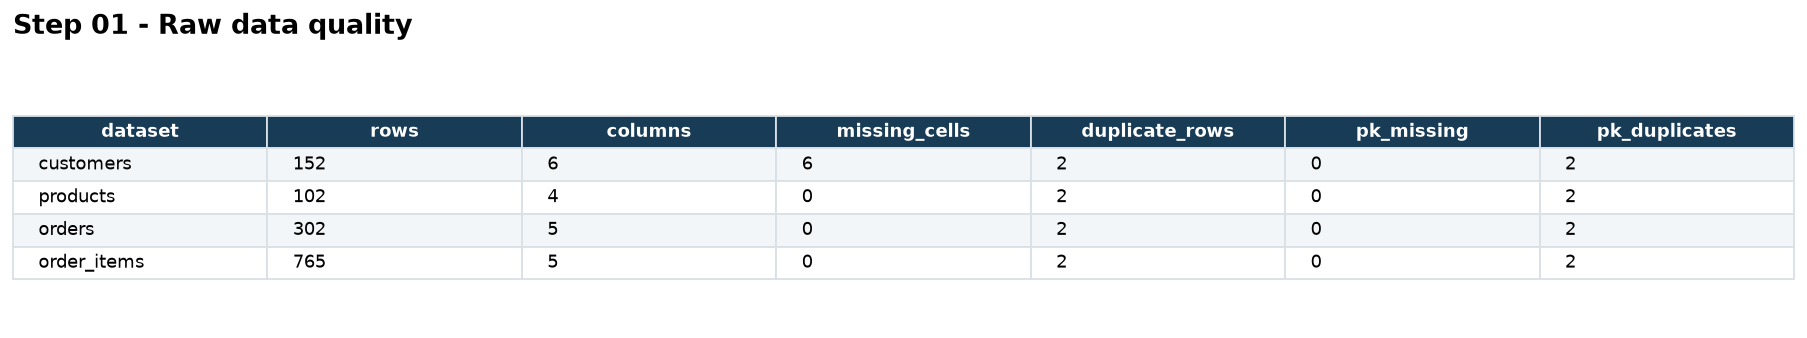

Evidence: step01_before.png (실제 실행 표; Notebook 내장 PNG)


In [41]:
raw_quality = quality(raw_data)
display(raw_quality)
display(official_missing_table)
print('원본 데이터 타입')
display(pd.concat([df.dtypes.astype(str).rename('dtype').rename_axis('column').reset_index().assign(dataset=name)
                   for name, df in raw_data.items()], ignore_index=True)[['dataset', 'column', 'dtype']])
raw_relationships = validate_relationships(raw_data)
display(raw_relationships)
print('상세 order_id 반복:', int(raw_data['order_items']['order_id'].duplicated().sum()))
evidence_table(raw_quality, 'Step 01 - Raw data quality', 'step01_before.png')

## 2. 문자열·타입·결측 처리

- 문자열은 결측을 유지한 채 앞뒤 공백을 제거하고, 정리 후 빈 문자열은 `pd.NA`로 바꾸는 규칙을 적용했다. 이번 데이터의 공백 변화는 city 5셀, category 3셀, payment_method 5셀(총 13셀)이며 빈 문자열에서 새 결측으로 바뀐 것은 0셀이다.
- 숫자 변환은 age, price, quantity, unit_price이다. 완전 중복 제거 후 각각 150·100·763·763행을 검사했고 **새 실패는 2·2·5·2건**이다. price 4셀과 unit_price 5셀의 쉼표를 제거했다.
- 날짜 변환은 signup_date와 order_date이다. 새 실패는 각각 **2·3건**이다. 주문일 범위는 **2025-07-01~2028-12-31**이며, 2027-01-15와 2028-12-31은 작성일보다 미래인 후보이다.
- age의 기존 결측 4건과 새 변환 실패 2건, 총 6건을 기록한 뒤 중앙값 **41세**로 대체했다. city 결측 2건은 `Unknown`으로 남겼다. ID·핵심 날짜·금액은 임의 대체하지 않았다.

### 결과 관찰

문자열 정리만 한 직후 결측은 6셀로 유지됐다. 모든 숫자·날짜를 변환한 직후에는 22셀이다. 이후 age 6셀과 city 2셀을 채우면 14셀, 계산 불가 숫자 행을 분석 범위에서 제외하면 원본 컬럼의 결측은 날짜 5셀만 남는다. 변환 실패를 채우거나 필터링하기 **전에** 기록했기 때문에 실패가 0건인 것처럼 보이지 않는다.

### 나의 해석과 판단

age 중앙값은 극단값 150의 영향을 평균보다 적게 받는 실습 기준이다. 다만 41이 해당 고객의 실제 나이라는 뜻은 아니며, 변환 실패도 원래 비어 있던 값과 구분해 기록했다. 고객을 삭제하면 연결된 주문 분석에도 영향을 줄 수 있어 고객 행은 보존했다. city는 최빈 도시로 추정하지 않고 Unknown으로 남겨 지역을 알 수 없는 집단을 구분했다. `3개`를 3으로 추정하거나 `three`를 3으로 바꾸는 규칙은 공식 숫자 변환 범위에 없으므로 추정하지 않았다.

### 업무·분석적 의미

숫자형 전환은 곱셈·합계를 가능하게 하고 날짜형 전환은 월·요일 계산을 가능하게 한다. 결측 대체는 고객 수 보존에 도움이 되지만 나이 분포를 41세 쪽으로 모을 수 있어 연령별 EDA에서 대체 건수를 함께 설명해야 한다.

### 한계와 추가 확인 사항

고객 ID 65·109의 가입일, 주문 ID 72·143·214의 주문일은 유효 날짜로 복구되지 않아 NaT로 보류했다. age 150은 결측이 아니므로 중앙값으로 바꾸지 않았다. 날짜가 해석 가능하더라도 미래 날짜가 업무상 맞는지는 별도 확인해야 한다.

,dataset,column,trimmed,empty_to_na,missing_after
0,customers,name,0,0,0
1,customers,gender,0,0,0
2,customers,age,0,0,4
3,customers,city,5,0,2
4,customers,signup_date,0,0,0
5,products,product_name,0,0,0
6,products,category,3,0,0
7,products,price,0,0,0
8,orders,order_date,0,0,0
9,orders,payment_method,5,0,0


,dataset,column,kind,rows_checked,missing_before,comma_removed,new_failures,missing_immediately_after
0,customers,age,numeric,150,4,0,2,6
1,products,price,numeric,100,0,4,2,2
2,order_items,quantity,numeric,763,0,0,5,5
3,order_items,unit_price,numeric,763,0,5,2,2
4,customers,signup_date,date,150,0,0,2,2
5,orders,order_date,date,300,0,0,3,3


,dataset,operation,affected
4,customers,age median imputation (41.0),6
5,customers,city Unknown,2


문자열 정리 직후 결측: 6
변환 직후 결측: 22
order_date 범위: 2025-07-01 00:00:00 ~ 2028-12-31 00:00:00
customers signup_date 원래 값


,customer_id,signup_date
64,65,2026-13-40
108,109,not-a-date


orders order_date 원래 값


,order_id,order_date
71,72,not-a-date
142,143,2026-02-30
213,214,2026/99/99


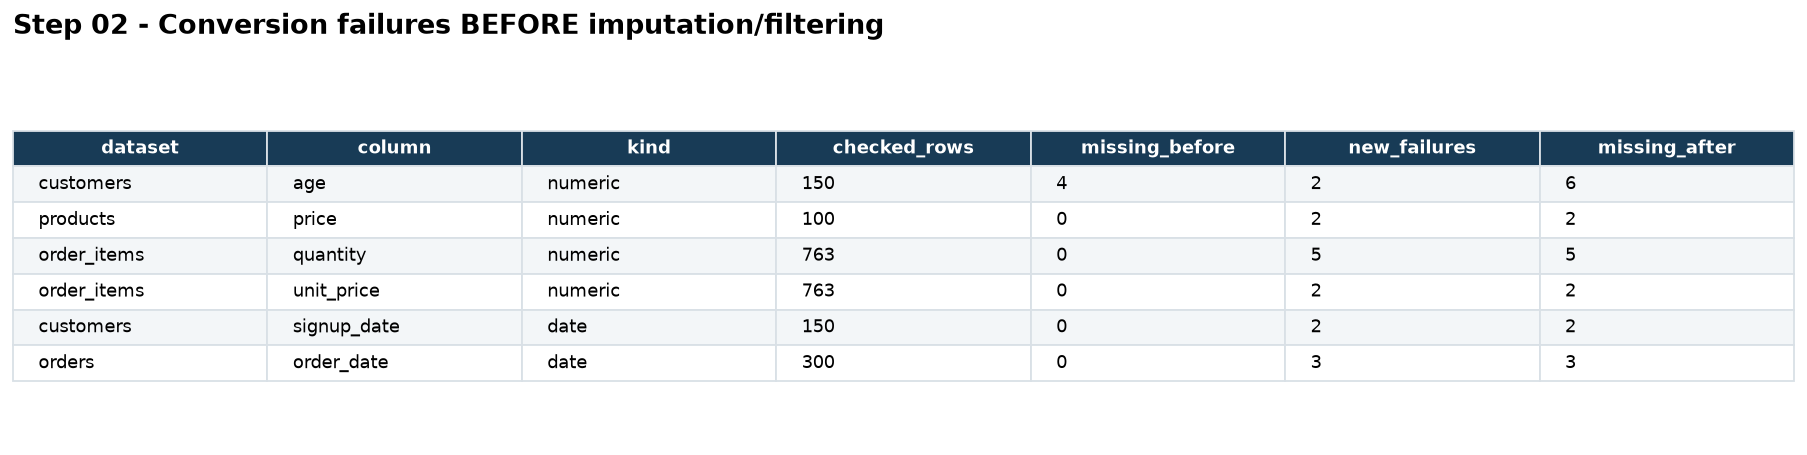

Evidence: step02_cleaning.png (실제 실행 표; Notebook 내장 PNG)


In [42]:
display(audit_evidence['strings'])
display(audit_evidence['conversions'])
display(audit_evidence['operations'].loc[lambda d: d['operation'].str.contains('imputation|Unknown', regex=True)])
print('문자열 정리 직후 결측:', int(audit_evidence['stages']['strings']['missing_cells'].sum()))
print('변환 직후 결측:', int(audit_evidence['stages']['converted']['missing_cells'].sum()))
print('order_date 범위:', final_data['orders']['order_date'].min(), '~', final_data['orders']['order_date'].max())
for dataset, col in [('customers', 'signup_date'), ('orders', 'order_date')]:
    pk = {'customers': 'customer_id', 'orders': 'order_id'}[dataset]
    invalid_ids = final_data[dataset].loc[final_data[dataset][col].isna(), pk]
    print(dataset, col, '원래 값')
    display(raw_data[dataset].loc[raw_data[dataset][pk].isin(invalid_ids), [pk, col]])
evidence_table(audit_evidence['conversions'].drop(columns='comma_removed').rename(columns={'rows_checked': 'checked_rows', 'missing_immediately_after': 'missing_after'}),
               'Step 02 - Conversion failures BEFORE imputation/filtering', 'step02_cleaning.png')

## 3. 중복·범주 표준화·이상값 후보

- 제거한 완전 중복: 각 파일 2행씩, 총 8행. 완전 중복 제거 후 주요 PK 중복·결측은 모두 0이다. 속성이 다른 동일 PK를 임의로 선택하거나 관계용 order_id 반복을 제거하지 않았다.
- 주문 상태: 공식 status_map으로 15셀을 통일했다. 최종 completed 180건, cancelled 63건, refunded 57건이며 허용값 밖 값은 0건이다. cancelled·refunded는 오류로 보지 않고 전처리 결과에 유지했다.
- 카테고리: 공백 3셀을 정리한 뒤 `전자 기기→전자기기`, `생활 용품→생활용품`, `뷰 티→뷰티` 3셀을 통일했다. 최종 7개 카테고리이며 정한 허용값 밖 값은 0건이다.
- 정상 양수 분석 범위에서 상품 4행, 상세 11행을 제외했다. 상품은 가격 변환 실패 2·비양수 2행이고, 상세는 수량 변환 실패 5·비양수 3행, 단가 변환 실패 2·비양수 1행이다. 제외 사유 표에 PK를 남겼고 raw는 보존했다.
- 보류 후보 6행: 고객 33의 age 150, 상품 99의 price 9,999,999, 상세 738·751의 quantity 50·100, 주문 256·287의 미래 날짜. 자동 삭제하지 않았다.

### 결과 관찰

가격·수량·단가의 `>0` 필터는 비양수뿐 아니라 NaN도 제외한다. 따라서 공식 필터에서 줄어든 행 전체를 '0 이하 이상값'이라고 설명하면 잘못이다. 상품 4행을 제외하면 이를 참조하던 정상 수량·단가 상세 24행이 부모 상품을 잃는다. 원래 없던 상품 ID 2행과 합쳐 최종 상품 FK 불일치는 26행이다.

### 나의 해석과 판단

0원은 증정품, 음수 수량은 반품일 수 있다. 이번 과제에서는 공식 예시의 양수 분석 범위를 적용하되 이를 업무 오류 확정이나 원본 삭제로 해석하지 않았다. 높은 양수에도 업무 의미가 있을 수 있어 값이 크다는 이유만으로 버리지 않았다. 가격 1,000,000 초과·수량 20 초과는 **검토 후보를 고르는 임시 기준**이며 적정 가격·수량의 업무 규칙이 아니다.

### 업무·분석적 의미

범주 표준화는 같은 그룹이 표기 차이로 쪼개지는 것을 막는다. 반대로 근거 없는 범주 통합은 다른 상품군을 섞을 수 있다. parent 행을 제외한 뒤 FK를 재검증해야 병합·카테고리 집계에서 금액이 누락되는 문제를 찾을 수 있다.

### 한계와 추가 확인 사항

가상의 학습 데이터라는 점 외에는 가격·나이·반품 규칙을 확정할 근거가 없다. 별칭 매핑은 표시된 세 경우로 한정했다. 후보값, 변환 불가 문자열, 없는 ID의 의미는 원본 기록과 담당자에게 확인해야 한다.

,dataset,operation,affected
0,customers,exact duplicate removal,2
1,products,exact duplicate removal,2
2,orders,exact duplicate removal,2
3,order_items,exact duplicate removal,2
4,customers,age median imputation (41.0),6
5,customers,city Unknown,2
6,orders,status normalization,15
7,products,category alias normalization,3
8,products,numeric eligibility exclusion (unique rows),4
9,order_items,numeric eligibility exclusion (unique rows),11


,dataset,primary_key,reason
0,products,18,price:conversion_failed_or_missing;
1,products,48,price:nonpositive;
2,products,73,price:conversion_failed_or_missing;
3,products,95,price:nonpositive;
4,order_items,17,quantity:conversion_failed_or_missing;
5,order_items,91,quantity:conversion_failed_or_missing;
6,order_items,205,quantity:conversion_failed_or_missing;
7,order_items,277,unit_price:conversion_failed_or_missing;
8,order_items,319,quantity:conversion_failed_or_missing;
9,order_items,433,unit_price:conversion_failed_or_missing;


,dataset,primary_key,column,value,reason,decision
0,customers,33,age,150.0,outside 0..120,retain; review business meaning
1,products,99,price,9999999.0,"above review threshold 1,000,000",retain; review business meaning
2,order_items,738,quantity,50.0,above review threshold 20,retain; review business meaning
3,order_items,751,quantity,100.0,above review threshold 20,retain; review business meaning
4,orders,256,order_date,2027-01-15 00:00:00,after assignment date 2026-10-14,retain; review business meaning
5,orders,287,order_date,2028-12-31 00:00:00,after assignment date 2026-10-14,retain; review business meaning


주문 상태 전/후


,raw,clean
order_status,,
completed,175,180
cancelled,59,63
refunded,53,57
Complete,2,0
cancel,2,0
Refund,2,0
complete,1,0
COMPLETED,1,0
완료,1,0


카테고리 전/후


,raw,clean
category,,
뷰티,17,17
식품,17,16
패션,16,16
도서,15,13
전자기기,12,14
스포츠,11,10
생활용품,8,10
전자기기,1,0
전자 기기,1,0


허용값 밖 주문 상태 / 카테고리: 0 / 0
보류 후보의 원래 값은 raw에 남아 있음: 6


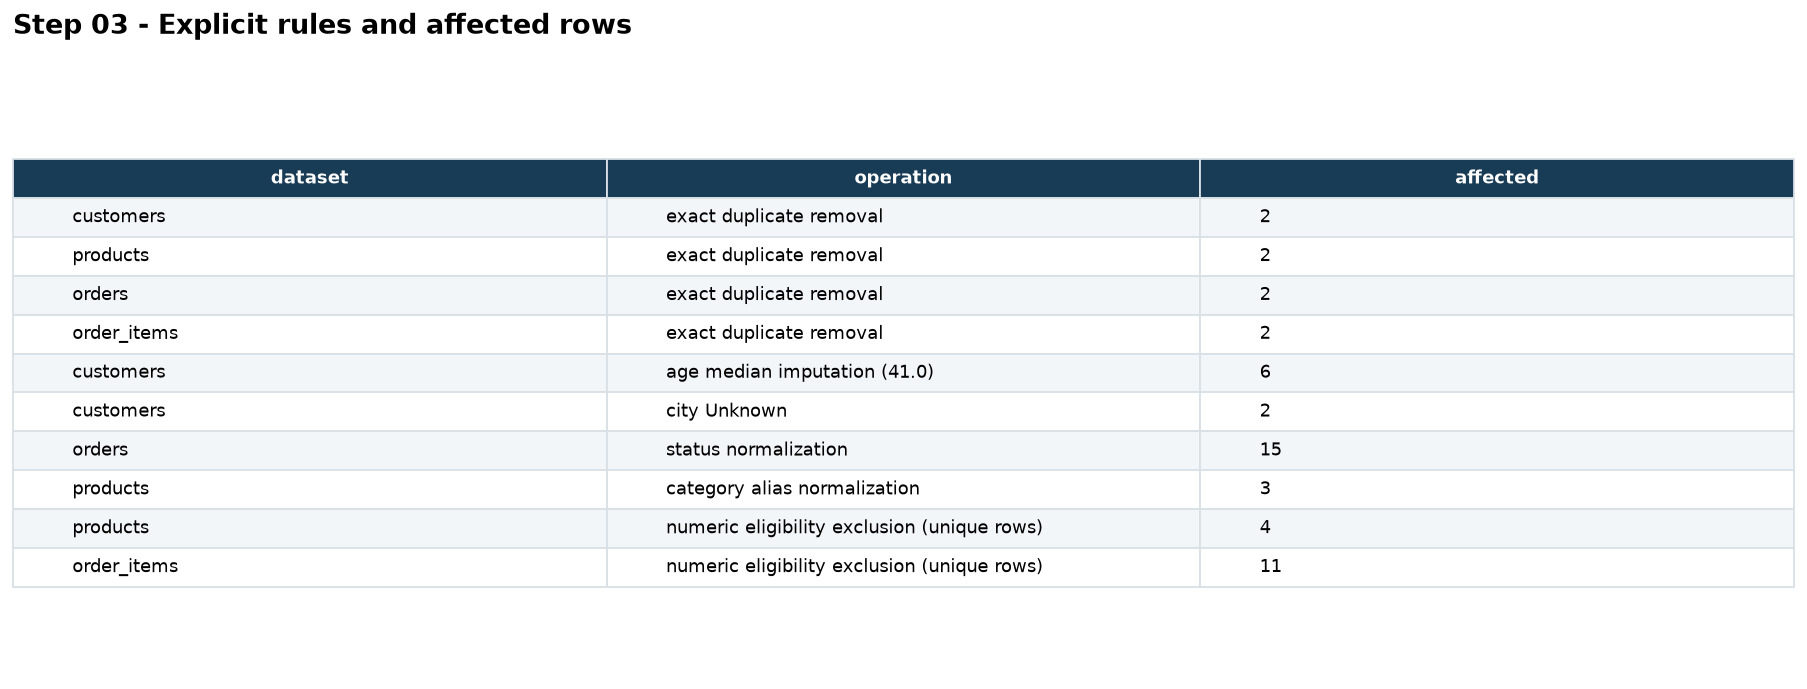

Evidence: step03_rules.png (실제 실행 표; Notebook 내장 PNG)


In [43]:
display(audit_evidence['operations'])
display(audit_evidence['rejected'])
display(audit_evidence['candidates'])
print('주문 상태 전/후')
display(pd.concat([raw_data['orders']['order_status'].value_counts(dropna=False).rename('raw'),
                   final_data['orders']['order_status'].value_counts(dropna=False).rename('clean')], axis=1).fillna(0))
print('카테고리 전/후')
display(pd.concat([raw_data['products']['category'].value_counts(dropna=False).rename('raw'),
                   final_data['products']['category'].value_counts(dropna=False).rename('clean')], axis=1).fillna(0))
allowed_categories = {'전자기기', '생활용품', '패션', '뷰티', '식품', '도서', '스포츠'}
assert audit_evidence['unexpected_status'].empty
assert final_data['products']['category'].isin(allowed_categories).all()
print('허용값 밖 주문 상태 / 카테고리: 0 / 0')
print('보류 후보의 원래 값은 raw에 남아 있음:', len(audit_evidence['candidates']))
evidence_table(audit_evidence['operations'], 'Step 03 - Explicit rules and affected rows', 'step03_rules.png')

## 4. PK/FK와 파생 컬럼 재검증

- 없는 customer_id: orders의 **2행**(9991·9992).
- 없는 order_id: order_items의 **2행**(9991·9992).
- 없는 product_id: order_items의 **26행**, 서로 다른 상품 ID 6개(18·48·73·95·9991·9992). 원래 불일치 2행과 상품 제외로 새로 생긴 불일치 24행이다.
- 최종 주요 PK 결측·중복: 네 파일 모두 0.
- 파생 컬럼: 주문의 order_month, order_dayofweek; 상세의 line_total.
- line_total: quantity × unit_price를 752행 모두 다시 계산해 일치했고 결측·불일치 0이다. 합계는 **252,140,000**이며 모든 주문 상태와 미매칭 상세를 포함하는 '전처리 후 전체 상세 금액'이다.

### 결과 관찰

FK 검사는 실행에 성공했지만 **참조 무결성은 통과하지 못했다**. 부모를 잃은 행을 숨기기 위해 삭제하거나 임의 부모를 만들지 않았다. 월별 고유 주문 수는 날짜 결측 그룹까지 합쳐 300건이다. 주문일 결측 3건의 월·요일도 각각 3건 결측으로 유지한다.

### 나의 해석과 판단

전처리 전 FK를 확인하는 것만으로 충분하지 않았다. 상품 제외 후 product FK 불일치가 2→26행으로 증가했기 때문이다. 이후 병합은 PK 고유성 확인 후 left merge, validate='many_to_one', indicator를 사용하고 행 수·line_total 합계 보존을 다시 검사한다. 고아 행은 복구 요청이나 분석 범위의 별도 제외 정책을 정하기 전까지 보류한다.

높은 수량 두 행의 금액 합계는 20,300,000으로 전체 상세 금액의 약 8.05%이다. 이처럼 합계가 맞아도 극단값·미래 날짜·주문 상태의 의미까지 검증된 것은 아니다. 월별 EDA에서는 NaT 그룹과 미래 날짜를 따로 설명하고, 매출로 해석하려면 completed 및 참조·기간 조건을 추가해야 한다.

,check,raw_invalid,clean_invalid
0,orders.customer_id exists in customers.custome...,2,2
1,order_items.order_id exists in orders.order_id,2,2
2,order_items.product_id exists in products.prod...,2,26


,dataset,pk_missing,pk_duplicates
0,customers,0,0
1,products,0,0
2,orders,0,0
3,order_items,0,0


,order_id,customer_id
0,126,9991
1,278,9992


,order_item_id,order_id
0,150,9991
1,620,9992


,order_item_id,product_id
0,22,73
1,32,48
2,77,18
3,90,48
4,99,48
5,106,48
6,130,48
7,214,95
8,242,95
9,260,9991


...

,order_month,order_count
0,2025-07,19
1,2025-08,26
2,2025-09,12
3,2025-10,22
4,2025-11,23
5,2025-12,23
6,2026-01,26
7,2026-02,19
8,2026-03,22
9,2026-04,26


월별 주문 건수 검증: 유효 날짜 297건 + 날짜 결측 3건 = 300건


,customer_id,age
32,33,150.0


,order_item_id,order_id,product_id,quantity,unit_price,line_total
750,751,295,31,100.0,155000.0,15500000.0
737,738,290,96,50.0,96000.0,4800000.0
319,320,129,23,5.0,197000.0,985000.0
9,10,5,65,5.0,193000.0,965000.0
20,21,9,36,5.0,193000.0,965000.0
24,25,11,65,5.0,193000.0,965000.0
116,117,51,65,5.0,193000.0,965000.0
293,294,119,36,5.0,193000.0,965000.0
290,291,117,47,5.0,188000.0,940000.0
10,11,6,97,5.0,187000.0,935000.0


고수량(>20) 두 행 합계: 20300000.0


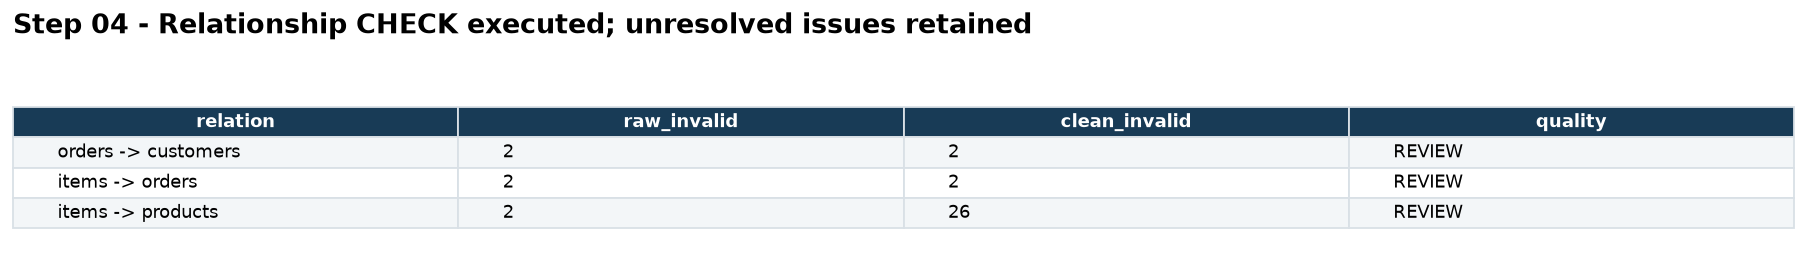

Evidence: step04_validation.png (실제 실행 표; Notebook 내장 PNG)


In [44]:
relationships_before_after = raw_relationships.rename(columns={'invalid_count': 'raw_invalid'}).merge(
    audit_evidence['relationships'].rename(columns={'invalid_count': 'clean_invalid'}), on='check')
display(relationships_before_after)
display(quality(final_data)[['dataset', 'pk_missing', 'pk_duplicates']])
for child, fk, parent, pk in [('orders', 'customer_id', 'customers', 'customer_id'),
                              ('order_items', 'order_id', 'orders', 'order_id'),
                              ('order_items', 'product_id', 'products', 'product_id')]:
    orphan = final_data[child].loc[~final_data[child][fk].isin(final_data[parent][pk])]
    display(orphan[[orphan.columns[0], fk]].reset_index(drop=True))
expected_line_total = final_data['order_items']['quantity'] * final_data['order_items']['unit_price']
assert expected_line_total.equals(final_data['order_items']['line_total'])
assert final_data['order_items']['line_total'].notna().all()
print('752행 line_total 재계산: PASS; 합계:', float(expected_line_total.sum()))
orders_month = final_data['orders'].groupby('order_month', dropna=False).agg(order_count=('order_id', 'nunique')).reset_index()
display(orders_month)
assert orders_month['order_count'].sum() == 300
print('월별 주문 건수 검증: 유효 날짜 297건 + 날짜 결측 3건 = 300건')
display(final_data['customers'].loc[lambda d: d['age'].lt(18) | d['age'].gt(100), ['customer_id', 'age']])
display(final_data['order_items'].sort_values(['line_total', 'order_item_id'], ascending=[False, True]).head(10))
print('고수량(>20) 두 행 합계:', float(final_data['order_items'].loc[lambda d: d['quantity'].gt(20), 'line_total'].sum()))
evidence_table(pd.DataFrame({'relation': ['orders -> customers', 'items -> orders', 'items -> products'],
                            'raw_invalid': relationships_before_after['raw_invalid'].tolist(),
                            'clean_invalid': relationships_before_after['clean_invalid'].tolist(),
                            'quality': ['REVIEW', 'REVIEW', 'REVIEW']}),
               'Step 04 - Relationship CHECK executed; unresolved issues retained', 'step04_validation.png')

In [45]:
# 이후 분석을 위한 점검: left merge는 미매칭 행과 금액을 보존한다.
detail_check = final_data['order_items'].merge(
    final_data['orders'][['order_id', 'customer_id', 'order_date', 'order_status']],
    on='order_id', how='left', validate='many_to_one', indicator='orders_match')
detail_check = detail_check.merge(final_data['products'][['product_id', 'category']],
    on='product_id', how='left', validate='many_to_one', indicator='products_match')
detail_check = detail_check.merge(final_data['customers'][['customer_id', 'city']],
    on='customer_id', how='left', validate='many_to_one', indicator='customers_match')
assert len(detail_check) == len(final_data['order_items'])
assert detail_check['line_total'].sum() == final_data['order_items']['line_total'].sum()
merge_audit = pd.DataFrame([{'merge': col, 'rows_before': 752, 'rows_after': len(detail_check),
                            'left_only': int(detail_check[col].eq('left_only').sum()),
                            'both': int(detail_check[col].eq('both').sum())}
                           for col in ['orders_match', 'products_match', 'customers_match']])
display(merge_audit)
print('left merge 행 수·금액 보존: PASS; 미매칭 행 자동 삭제 없음')
# 참고 분석 범위의 예시이다. 최종 clean 데이터의 삭제 규칙과 구분한다.
eligible_mask = (detail_check['orders_match'].eq('both') & detail_check['products_match'].eq('both') &
                 detail_check['customers_match'].eq('both') & detail_check['order_date'].notna() &
                 detail_check['order_date'].le(REFERENCE_DATE) & detail_check['order_status'].eq('completed'))
print('참고: 연결·날짜·작성일 이전·completed 조건 상세', int(eligible_mask.sum()), '행, 금액',
      float(detail_check.loc[eligible_mask, 'line_total'].sum()))
print('이 참고값은 할인/세금/배송/원가를 반영한 순매출·이익이 아니다.')

,merge,rows_before,rows_after,left_only,both
0,orders_match,752,752,2,750
1,products_match,752,752,26,726
2,customers_match,752,752,6,746


left merge 행 수·금액 보존: PASS; 미매칭 행 자동 삭제 없음


참고: 연결·날짜·작성일 이전·completed 조건 상세 420 행, 금액 134137000.0
이 참고값은 할인/세금/배송/원가를 반영한 순매출·이익이 아니다.


## 5. 전처리 전/후 비교

| 항목 | 처리 전 | 처리 후 | 변화 이유 |
| --- | ---: | ---: | --- |
| customers 행 | 152 | 150 | 완전 중복 2행 |
| products 행 | 102 | 96 | 완전 중복 2행 + 가격 실패/비양수 4행 |
| orders 행 | 302 | 300 | 완전 중복 2행; 날짜 실패/FK 문제 행 보류 |
| order_items 행 | 765 | 752 | 완전 중복 2행 + 수량/단가 실패/비양수 11행 |
| 전체 결측 셀 | 6 | 11 | 나이·도시 대체 후 원본 날짜 결측 5 + 월/요일 파생 결측 6 |
| 원본 컬럼만의 결측 | 6 | 5 | age·city 결측 처리, 숫자 실패 행 범위 제외, 날짜 오류 보류 |
| 전체 행 중복 합계 | 8 | 0 | 네 파일 각 2행 제거 |
| 주요 PK 중복 합계 | 8 | 0 | 중복이 모두 완전 중복임을 확인한 뒤 제거 |
| 변환 불가 비결측 원문 | 숫자 11·날짜 5건 | 최종 원본 날짜 결측 5셀 | age 실패 2 대체, 가격/수량/단가 실패 9행 제외; 날짜 5셀 보류 |
| 열 수 | 6 / 4 / 5 / 5 | 6 / 4 / 7 / 6 | 주문 월·요일, 상세 금액 추가 |
| FK 불일치 행 (고객/주문/상품) | 2 / 2 / 2 | 2 / 2 / 26 | 제외된 상품을 참조하던 상세 24행이 추가로 미매칭 |

숫자/날짜 신규 변환 실패 11·5건은 **변환 직후의 기록**이다. 원본 상태에서는 실패 여부가 계산되지 않았으므로 기존 isna 결과 0을 '변환 실패 0'이라고 부르지 않는다. 파생 결측은 원본 날짜 오류를 재표현한 것이므로 11셀이 서로 독립적인 오류 11개를 뜻하지도 않는다.

### 결과 관찰

총 행 수는 1,321→1,298(23행 감소)이다. 8행은 완전 중복, 15행은 숫자 분석 범위 제외로 설명된다. 날짜 실패·FK 불일치·극단값 후보는 보류해서 정상으로 꾸미지 않았다. 원본 파일 해시와 원본 DataFrame 내용은 전처리 후에도 동일했다.

### 나의 해석과 판단

행 감소를 제외 사유와 대조하고, 카테고리·상태 분포를 원본과 비교했다. 완료 상태 180건은 정상화와 중복 제거 후의 고유 주문 수이다. age의 실제 숫자 144건은 바꾸지 않고 결측/실패 6건만 41로 대체했다. 중앙값 대체 전 유효 나이 평균은 약 44.03세, 대체 후 평균은 약 43.91세여서 작은 값 변화도 대체의 영향임을 확인했다.

### 업무·분석적 의미

결측이 감소했는지만 보지 않고 어떤 값이 제외·대체·보류됐는지 설명해야 한다. 파생 컬럼 때문에 결측 총합이 늘 수 있고, parent 제외 때문에 관계 품질이 나빠질 수도 있다.

### 한계와 추가 확인 사항

행 수·합계·해시가 맞아도 값의 업무상 진실성이 증명되지는 않는다. 미래 날짜·비정상 나이·극단 가격·수량·부모 ID 누락에 대한 업무 확인이 여전히 필요하다.

,dataset,rows_raw,columns_raw,missing_cells_raw,duplicate_rows_raw,pk_missing_raw,pk_duplicates_raw,rows_clean,columns_clean,missing_cells_clean,duplicate_rows_clean,pk_missing_clean,pk_duplicates_clean
0,customers,152,6,6,2,0,2,150,6,2,0,0,0
1,products,102,4,0,2,0,2,96,4,0,0,0,0
2,orders,302,5,0,2,0,2,300,7,9,0,0,0
3,order_items,765,5,0,2,0,2,752,6,0,0,0,0


,dataset,raw_rows,duplicate_removed,numeric_excluded,clean_rows
0,customers,152,2,0,150
1,products,102,2,4,96
2,orders,302,2,0,300
3,order_items,765,2,11,752


원본 컬럼 결측: 5 전체 결측: 11
대체 전 유효 나이 평균: 44.03472222222222 대체 후: 43.913333333333334
원본 DataFrame 내용 + CSV SHA-256 보존: PASS


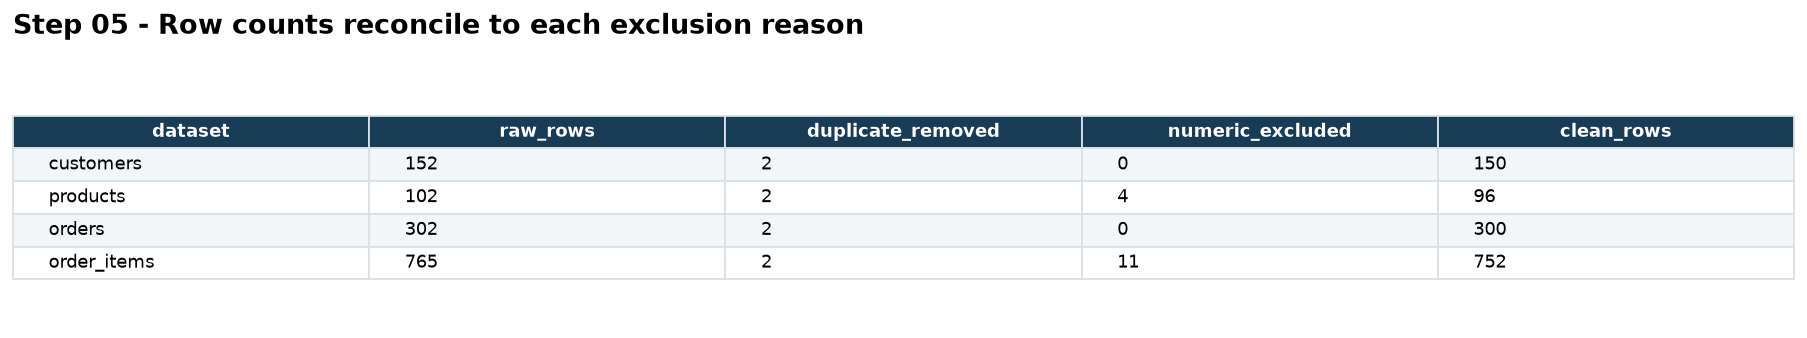

Evidence: step05_before_after.png (실제 실행 표; Notebook 내장 PNG)


In [46]:
before_after = quality(raw_data).merge(quality(final_data), on='dataset', suffixes=('_raw', '_clean'))
display(before_after)
row_accounting = pd.DataFrame([{
    'dataset': name, 'raw_rows': len(df),
    'duplicate_removed': int(df.duplicated().sum()),
    'numeric_excluded': int(audit_evidence['rejected']['dataset'].eq(name).sum()),
    'clean_rows': len(final_data[name]),
} for name, df in raw_data.items()])
assert (row_accounting['raw_rows'] - row_accounting['duplicate_removed'] - row_accounting['numeric_excluded']).equals(row_accounting['clean_rows'])
display(row_accounting)
original_columns_missing = sum(int(final_data[name][raw_data[name].columns].isna().sum().sum()) for name in raw_data)
print('원본 컬럼 결측:', original_columns_missing, '전체 결측:', int(quality(final_data)['missing_cells'].sum()))
age_raw_numeric = pd.to_numeric(raw_data['customers'].drop_duplicates()['age'], errors='coerce')
print('대체 전 유효 나이 평균:', float(age_raw_numeric.mean()), '대체 후:', float(final_data['customers']['age'].mean()))
for name, df in raw_data.items():
    pd.testing.assert_frame_equal(df, RAW_SNAPSHOTS[name])
assert RAW_HASHES_BEFORE == {p.name: sha256(p) for p in sorted(RAW_DIR.glob('*.csv'))}
print('원본 DataFrame 내용 + CSV SHA-256 보존: PASS')
evidence_table(row_accounting, 'Step 05 - Row counts reconcile to each exclusion reason', 'step05_before_after.png')

## 6. 재현 가능한 전처리 확인

- 생성된 clean CSV: `data/processed/customers_clean.csv`, `products_clean.csv`, `orders_clean.csv`, `order_items_clean.csv`.
- 생성된 보고서: `reports/ch05_preprocessing_summary.md`. 크기·중복·문자열·숫자/날짜 실패·처리 건수·제외 사유·보류 후보·FK·파생 컬럼·업무 한계를 포함한다.
- 공식 스크립트 원문은 A에서 2회 실행했다. B에서는 공식 스크립트를 `scripts/preprocess_data_official.py`로 복사 보존하고, 같은 `scripts/preprocess_data.py` 명령이 보완 모듈을 실행하게 한다. 경로 설정과 보완 모듈 호출만 변경한다.
- Notebook에서 만든 최종 CSV와 보고서의 해시를 기록한 뒤 새 Python 프로세스에서 2회 재실행한다. 각 종료 코드 0, 결과 5파일 해시 동일, 원본 해시 동일을 검증한다. 저장 CSV를 다시 읽어 전체 값·shape·컬럼·PK/FK·날짜 재변환·파생 계산을 확인한다.

### 나의 해석과 판단

Notebook 한 번의 성공은 이전 셀의 변수 상태에 의존할 수 있다. 스크립트의 새 프로세스 실행은 CSV 원본에서 다시 시작하므로 숨은 변수 없이 같은 규칙을 적용하는지 확인할 수 있다. 해시 일치는 재현성을 뜻하고 데이터 품질 오류 해결을 뜻하지 않는다. 따라서 재실행 후에도 FK 2·2·26과 날짜 실패 2·3을 그대로 보고한다.

출력 경로는 첫 셀에 표시된 임시 프로젝트 아래이며, 이 파일을 다시 실행하면 동일한 CSV·보고서가 재생성된다. 증빙은 현재 Notebook의 출력에 포함되어 별도의 images 폴더가 필요 없다.

보완 스크립트 재실행 1 returncode: 0
전처리 완료 (품질 오류는 아래 결과로 별도 확인)
    dataset  rows  columns  missing_cells  duplicate_rows  pk_missing  pk_duplicates
  customers   150        6              2               0           0              0
   products    96        4              0               0           0              0
     orders   300        7              9               0           0              0
order_items   752        6              0               0           0              0
                                               check  invalid_count
  orders.customer_id exists in customers.customer_id              2
      order_items.order_id exists in orders.order_id              2
order_items.product_id exists in products.product_id             26
숫자/날짜 신규 실패: 16
제외: 15 보류 후보: 6
data/processed/customers_clean.csv 5773 bytes
data/processed/products_clean.csv 3871 bytes
data/processed/orders_clean.csv 16120 bytes
data/processed/order_items_clean.csv 23918 bytes
reports/ch05_preprocessing_sum

보완 스크립트 재실행 2 returncode: 0


,run,returncode,csv_and_report_hash_equal,raw_hash_unchanged
0,1,0,True,True
1,2,0,True,True


,file,exists,bytes,sha256
0,data/processed/customers_clean.csv,True,5773,f14a59af4a8a900c0b9f72c7fab3367df2ba1e1419f24f...
1,data/processed/order_items_clean.csv,True,23918,82389ef808e4f9db56ad76e52fe511b0face3f016cb817...
2,data/processed/orders_clean.csv,True,16120,b7264a74270919ae0b9c1d7bc999f7c0f472d97dfdf445...
3,data/processed/products_clean.csv,True,3871,b6a1f8263f815c9990f01049f87c17f9d45ed6b45d4583...
4,reports/ch05_preprocessing_summary.md,True,8666,82d86f9550043f46891d840a7bae5f8e37a7049bf2d9bf...


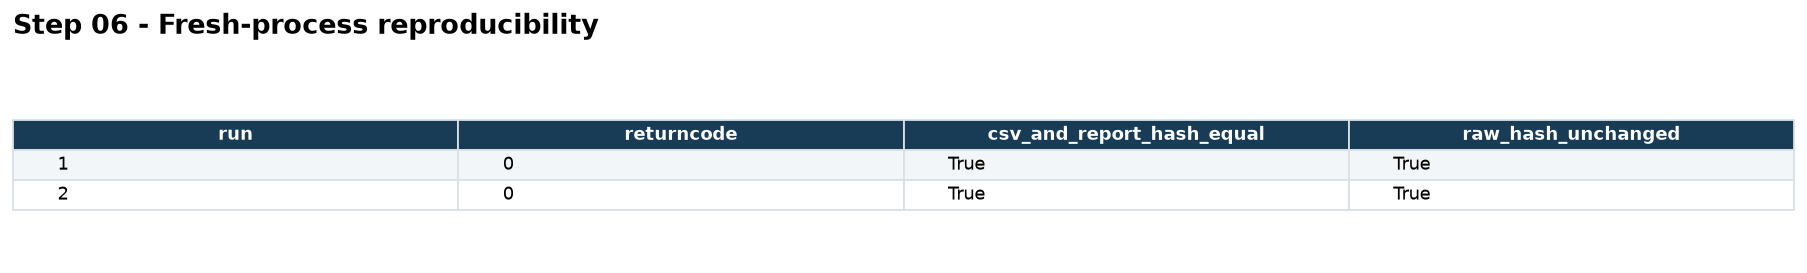

Evidence: step06_reproducible.png (실제 실행 표; Notebook 내장 PNG)


In [47]:
from src.preprocessing import save_processed_data

saved_paths = save_processed_data(final_data, PROCESSED_DIR)
report_path = REPORT_DIR / 'ch05_preprocessing_summary.md'
report_path.write_text(report_text(raw_data, final_data, audit_evidence), encoding='utf-8')
artifact_paths = sorted(saved_paths) + [report_path]
notebook_hashes = {p.relative_to(PROJECT_ROOT).as_posix(): sha256(p) for p in artifact_paths}

official_script = PROJECT_ROOT / 'scripts/preprocess_data.py'
official_backup = PROJECT_ROOT / 'scripts/preprocess_data_official.py'
official_backup.write_bytes(official_script.read_bytes())
assert sha256(official_backup) == SOURCE_MANIFEST['files']['scripts/preprocess_data.py']['sha256']
revised_script = "from pathlib import Path\nfrom src.submission_preprocessing import run_pipeline\n\nif __name__ == '__main__':\n    run_pipeline(Path.cwd())\n"
official_script.write_text(revised_script, encoding='utf-8')
rerun_results = []
for run in (1, 2):
    result = subprocess.run([sys.executable, 'scripts/preprocess_data.py'], cwd=PROJECT_ROOT,
                            env=script_env, text=True, capture_output=True, check=False)
    print('보완 스크립트 재실행', run, 'returncode:', result.returncode)
    assert result.returncode == 0, result.stderr
    if run == 1:
        print(result.stdout)
    hashes = {p.relative_to(PROJECT_ROOT).as_posix(): sha256(p) for p in artifact_paths}
    assert hashes == notebook_hashes
    rerun_results.append({'run': run, 'returncode': result.returncode, 'csv_and_report_hash_equal': True,
                          'raw_hash_unchanged': RAW_HASHES_BEFORE == {p.name: sha256(p) for p in RAW_DIR.glob('*.csv')}})
    assert rerun_results[-1]['raw_hash_unchanged']
display(pd.DataFrame(rerun_results))
artifact_manifest = pd.DataFrame([{'file': p.relative_to(PROJECT_ROOT).as_posix(),
                                  'exists': p.exists(), 'bytes': p.stat().st_size, 'sha256': sha256(p)}
                                 for p in artifact_paths])
assert artifact_manifest['exists'].all() and artifact_manifest['bytes'].gt(0).all()
display(artifact_manifest)
evidence_table(pd.DataFrame(rerun_results), 'Step 06 - Fresh-process reproducibility', 'step06_reproducible.png')

In [48]:
# CSV는 타입 정보를 저장하지 않으므로 명시적으로 날짜를 다시 변환한다.
reloaded = {name: pd.read_csv(PROCESSED_DIR / f'{name}_clean.csv') for name in final_data}
reload_audit = []
for name, df in reloaded.items():
    expected = final_data[name]
    assert df.shape == expected.shape
    assert df.columns.tolist() == expected.columns.tolist()
    for col in ['signup_date', 'order_date']:
        if col in df:
            before = df[col].copy()
            df[col] = pd.to_datetime(df[col], format='mixed', errors='coerce')
            newly_failed = int((before.notna() & df[col].isna()).sum())
            assert newly_failed == 0
            reload_audit.append({'dataset': name, 'column': col, 'new_reload_failures': newly_failed,
                                 'retained_date_missing': int(df[col].isna().sum())})
    pd.testing.assert_frame_equal(df, expected.reset_index(drop=True), check_dtype=False, check_freq=False)
display(pd.DataFrame(reload_audit))
display(validate_relationships(reloaded))
assert reloaded['order_items']['line_total'].eq(reloaded['order_items']['quantity'] * reloaded['order_items']['unit_price']).all()
assert reloaded['orders'].loc[reloaded['orders']['order_date'].isna(), ['order_month', 'order_dayofweek']].isna().all().all()
print('저장 재로드: 4파일 shape·컬럼·전체 값·PK/FK·line_total 재검증 PASS')
print('재로드 신규 날짜 변환 실패 0; 기존 가입일 2 / 주문일 3 결측은 보류 상태로 유지')
display(Markdown(report_path.read_text(encoding='utf-8')))

,dataset,column,new_reload_failures,retained_date_missing
0,customers,signup_date,0,2
1,orders,order_date,0,3


,check,invalid_count
0,orders.customer_id exists in customers.custome...,2
1,order_items.order_id exists in orders.order_id,2
2,order_items.product_id exists in products.prod...,26


저장 재로드: 4파일 shape·컬럼·전체 값·PK/FK·line_total 재검증 PASS
재로드 신규 날짜 변환 실패 0; 기존 가입일 2 / 주문일 3 결측은 보류 상태로 유지


# Chapter 05 데이터 전처리 요약

## 입력과 결과 파일
입력: practice/chapter05/data/raw/ (공식 전용 Raw, 원본 보존)
결과: data/processed/customers_clean.csv, products_clean.csv, orders_clean.csv, order_items_clean.csv

## 전처리 전 상태
| dataset     |   rows |   columns |   missing_cells |   duplicate_rows |   pk_missing |   pk_duplicates |
|:------------|-------:|----------:|----------------:|-----------------:|-------------:|----------------:|
| customers   |    152 |         6 |               6 |                2 |            0 |               2 |
| products    |    102 |         4 |               0 |                2 |            0 |               2 |
| orders      |    302 |         5 |               0 |                2 |            0 |               2 |
| order_items |    765 |         5 |               0 |                2 |            0 |               2 |

## 전처리 후 상태
| dataset     |   rows |   columns |   missing_cells |   duplicate_rows |   pk_missing |   pk_duplicates |
|:------------|-------:|----------:|----------------:|-----------------:|-------------:|----------------:|
| customers   |    150 |         6 |               2 |                0 |            0 |               0 |
| products    |     96 |         4 |               0 |                0 |            0 |               0 |
| orders      |    300 |         7 |               9 |                0 |            0 |               0 |
| order_items |    752 |         6 |               0 |                0 |            0 |               0 |

## 문자열·빈 문자열
| dataset     | column         |   trimmed |   empty_to_na |   missing_after |
|:------------|:---------------|----------:|--------------:|----------------:|
| customers   | name           |         0 |             0 |               0 |
| customers   | gender         |         0 |             0 |               0 |
| customers   | age            |         0 |             0 |               4 |
| customers   | city           |         5 |             0 |               2 |
| customers   | signup_date    |         0 |             0 |               0 |
| products    | product_name   |         0 |             0 |               0 |
| products    | category       |         3 |             0 |               0 |
| products    | price          |         0 |             0 |               0 |
| orders      | order_date     |         0 |             0 |               0 |
| orders      | payment_method |         5 |             0 |               0 |
| orders      | order_status   |         0 |             0 |               0 |
| order_items | quantity       |         0 |             0 |               0 |
| order_items | unit_price     |         0 |             0 |               0 |

## 숫자·날짜 변환 실패
| dataset     | column      | kind    |   rows_checked |   missing_before |   comma_removed |   new_failures |   missing_immediately_after |
|:------------|:------------|:--------|---------------:|-----------------:|----------------:|---------------:|----------------------------:|
| customers   | age         | numeric |            150 |                4 |               0 |              2 |                           6 |
| products    | price       | numeric |            100 |                0 |               4 |              2 |                           2 |
| order_items | quantity    | numeric |            763 |                0 |               0 |              5 |                           5 |
| order_items | unit_price  | numeric |            763 |                0 |               5 |              2 |                           2 |
| customers   | signup_date | date    |            150 |                0 |               0 |              2 |                           2 |
| orders      | order_date  | date    |            300 |                0 |               0 |              3 |                           3 |

## 처리 기준과 영향 건수
| dataset     | operation                                   |   affected |
|:------------|:--------------------------------------------|-----------:|
| customers   | exact duplicate removal                     |          2 |
| products    | exact duplicate removal                     |          2 |
| orders      | exact duplicate removal                     |          2 |
| order_items | exact duplicate removal                     |          2 |
| customers   | age median imputation (41.0)                |          6 |
| customers   | city Unknown                                |          2 |
| orders      | status normalization                        |         15 |
| products    | category alias normalization                |          3 |
| products    | numeric eligibility exclusion (unique rows) |          4 |
| order_items | numeric eligibility exclusion (unique rows) |         11 |

## 제외 사유 (원본 삭제 아님)
| dataset     |   primary_key | reason                                   |
|:------------|--------------:|:-----------------------------------------|
| products    |            18 | price:conversion_failed_or_missing;      |
| products    |            48 | price:nonpositive;                       |
| products    |            73 | price:conversion_failed_or_missing;      |
| products    |            95 | price:nonpositive;                       |
| order_items |            17 | quantity:conversion_failed_or_missing;   |
| order_items |            91 | quantity:conversion_failed_or_missing;   |
| order_items |           205 | quantity:conversion_failed_or_missing;   |
| order_items |           277 | unit_price:conversion_failed_or_missing; |
| order_items |           319 | quantity:conversion_failed_or_missing;   |
| order_items |           433 | unit_price:conversion_failed_or_missing; |
| order_items |           447 | quantity:conversion_failed_or_missing;   |
| order_items |           511 | quantity:nonpositive;                    |
| order_items |           579 | unit_price:nonpositive;                  |
| order_items |           612 | quantity:nonpositive;                    |
| order_items |           703 | quantity:nonpositive;                    |

## 검토 후 보류한 이상값 후보
| dataset     |   primary_key | column     | value               | reason                           | decision                        |
|:------------|--------------:|:-----------|:--------------------|:---------------------------------|:--------------------------------|
| customers   |            33 | age        | 150.0               | outside 0..120                   | retain; review business meaning |
| products    |            99 | price      | 9999999.0           | above review threshold 1,000,000 | retain; review business meaning |
| order_items |           738 | quantity   | 50.0                | above review threshold 20        | retain; review business meaning |
| order_items |           751 | quantity   | 100.0               | above review threshold 20        | retain; review business meaning |
| orders      |           256 | order_date | 2027-01-15 00:00:00 | after assignment date 2026-10-14 | retain; review business meaning |
| orders      |           287 | order_date | 2028-12-31 00:00:00 | after assignment date 2026-10-14 | retain; review business meaning |

## PK/FK 재검증
| check                                                |   invalid_count |
|:-----------------------------------------------------|----------------:|
| orders.customer_id exists in customers.customer_id   |               2 |
| order_items.order_id exists in orders.order_id       |               2 |
| order_items.product_id exists in products.product_id |              26 |

## 파생 컬럼
order_month, order_dayofweek, line_total = quantity × unit_price. 날짜 실패는 NaT로 유지하고 월/요일도 결측으로 유지한다.

## 업무 적용 한계
완전 중복만 제거한다. PK 충돌은 자동 삭제하지 않는다. age의 기존 결측과 숫자 변환 실패는 구분해 기록한 뒤 실습 기준으로 중앙값을 대체한다. city는 Unknown으로 남긴다. ID·날짜·금액을 임의로 복구하지 않는다. 비양수 금액·수량과 숫자 변환 실패 행은 정상 양수 분석 범위에서만 제외하고 사유를 보존한다. 없는 FK는 자동 제거하지 않는다. FK 불일치와 날짜 실패, 미래 날짜, 극단값이 남아 있으므로 clean이라는 이름만으로 완전한 데이터 또는 확정 매출로 해석할 수 없다. 매출 분석에서는 completed 상태, 연결 가능한 키, 유효 날짜, 분석 기간을 명시해야 한다.


## 7. Chapter 05 최종 판단

### 내가 정한 전처리 원칙 3가지

1. **원본을 보존하고 확인 가능한 변화만 기록한다.** 파일 해시와 DataFrame 원본을 대조하고, 중복·대체·제외·보류를 구분한다.
2. **컬럼 의미에 따라 처리한다.** 나이는 실습 기준의 중앙값, 도시는 Unknown으로 처리한다. ID·날짜·금액을 추정하지 않고, 전체 중복과 FK 반복을 구분한다.
3. **처리 후 다시 검증하고 같은 입력에서 재현한다.** 변환 직후 실패, 전후 shape·분포, PK/FK, 파생 계산, 저장 재로드, 새 프로세스 반복 해시를 확인한다.

### 가장 위험하다고 생각한 자동 처리 1가지와 이유

참조 오류를 없애려고 없는 부모 ID를 가진 주문·상세를 일괄 삭제하는 처리이다. 숫자형 정리가 정상이어도 상품 제외 후 24개 상세가 부모를 잃었는데, 이를 또 삭제하면 금액과 카테고리 분포가 추가로 달라진다. 문제를 감추기 위해 invalid_count를 0으로 만드는 것이 아니라 오류 행과 원인을 남겨 복구 또는 목적별 제외를 결정해야 한다.

### 다음 EDA에서 특히 주의할 데이터 특성

완료 180·취소 63·환불 57건이 함께 있다. 전체 line_total 252,140,000은 확정 매출이 아니다. 가입일 실패 2·주문일 실패 3건, 미래 주문 2건, 고객/주문/상품 FK 2·2·26행을 별도로 고려해야 한다. 월별 그룹의 결측 3건을 조용히 버리지 말고 집계 범위에 표시한다. 150세와 가격 9,999,999, 수량 50·100은 값의 진위를 확인해야 한다. 41세 대체 6명·Unknown 도시 2명도 그룹 해석에 포함한다.

### 현재 전처리의 한계

형식·재현성·변경 경로를 검증했지만 업무상 정확성을 확정하지 못했다. 가격과 단가가 반드시 같은지도 이번 자료만으로 단정할 수 없다. 금액은 할인·배송·세금·원가가 없어서 순매출·수익이 아니며, 참조 오류가 남은 clean 파일을 무조건 EDA에 쓰면 안 된다. 보류값을 원본 시스템과 확인하고 분석별 포함 기준을 명시해야 한다.

### LLM 전처리 제안 검증 (가이드 STEP 17 / 공식 과제 6)

아래 프롬프트는 실제 고객명·원본 고객 행 대신 구조와 품질 요약만 제공한다. Codex에 의한 보완과 검증에 사용한 요구사항을 재현 가능한 형태로 기록한다.

```text
Chapter 05 가상 쇼핑몰 데이터 전처리 기준을 검토해 주세요.
중복 제거 후 customers 150행, 주요 PK 결측·충돌 0,
age 기존 결측 4 + 숫자 변환 실패 2, 유효값 중앙값 41,
age 150 후보 1, city 결측 2, signup_date 변환 실패 2입니다.
orders 300행, order_date 실패 3, 미래 날짜 후보 2,
최종 FK 불일치는 고객 2·주문 2·상품 26행입니다.
age 행 삭제/평균/중앙값 대체, city 최빈값/Unknown을 비교해 주세요.
원본 복사, 변환 직후 실패 기록, 전체 중복/PK 충돌/FK 반복 구분,
숫자 실패와 비양수의 별도 제외 사유, 이상값 보류,
PK/FK·파생 계산·새 프로세스 재현 검증을 포함해 주세요.
실제 업무 의미나 없는 ID·날짜를 추측하여 복구하지 마세요.
```

공식 검토 예시 코드는 raw에 age 평균을 직접 채우고, 기준 확인 없이 drop_duplicates를 수행하며, 날짜 실패·숫자형·범위·관계 검증이 부족했다. 평균은 150세 같은 극단값에 민감하고 최빈 도시 대체는 특정 도시를 부풀릴 수 있다. 채택한 제안은 복사본 사용, 중앙값/Unknown의 근거 설명, 변환 직후 감사표, 제외 사유 보존, 관계 재검증, 재현성 검사이다. 업무 오류 자동 확정·고아 행 자동 삭제는 채택하지 않았다. 최종 판단은 **검증 항목을 추가해 수정 후 사용, 남은 품질 문제는 보류**이다.

In [49]:
# 공식 LLM 검토 예시의 한계를 실제 격리 복사본에서 확인
llm_probe = {name: df.copy(deep=True) for name, df in raw_data.items()}
try:
    llm_probe['customers']['age'].fillna(llm_probe['customers']['age'].mean())
    print('raw age 평균 계산 성공 여부: 환경에서 직접 확인')
except (TypeError, ValueError) as error:
    print('raw age는 문자열 혼합으로 평균 계산 불가:', type(error).__name__)
try:
    pd.to_datetime(llm_probe['orders']['order_date'])
    print('기본 날짜 변환 성공')
except (TypeError, ValueError) as error:
    print('오류 처리 없는 날짜 변환 중단:', type(error).__name__)
try:
    llm_probe['order_items']['quantity'] * llm_probe['order_items']['unit_price']
    print('raw 문자열 곱셈 성공 여부: 환경에서 직접 확인')
except (TypeError, ValueError) as error:
    print('raw 수량·단가 문자열 곱셈 불가:', type(error).__name__)
for name in raw_data:
    pd.testing.assert_frame_equal(raw_data[name], RAW_SNAPSHOTS[name])
print('최종 원본 DataFrame 보존: PASS')

raw age는 문자열 혼합으로 평균 계산 불가: TypeError
오류 처리 없는 날짜 변환 중단: ValueError
raw 수량·단가 문자열 곱셈 불가: TypeError
최종 원본 DataFrame 보존: PASS


## Chapter 05 완료 Evidence

여기서 PASS는 **해당 확인 절차의 성공**이다. 남은 데이터 품질 오류는 별도로 표시한다.

- Notebook 코드 순차 실행: 모든 실행 셀 완료, 예상 오류 검토는 try/except 출력으로 기록.
- raw 원본 보존: PASS — 공식 원본 및 처리 전후 SHA-256, 원본 DataFrame 일치.
- processed CSV 4개 생성: PASS — 존재·비어 있지 않음·전체 값 재로드 확인.
- 숫자/날짜 변환 실패 점검: PASS — 숫자 신규 11건·날짜 신규 5건 기록. **날짜 품질: 보류 5건.**
- 전체 중복/키 중복 점검: PASS — 완전 중복 8행 제거, 최종 PK 중복/결측 0.
- PK/FK 관계 검사 실행: PASS. **참조 무결성: FAIL / 업무 확인 필요 — 2·2·26행.**
- 파생 컬럼 검증: PASS — 월/요일 결측 연동, 752행 line_total 재계산 및 월별 주문 300건 일치.
- preprocess_data.py 재실행: PASS — 공식 2회, 보완 2회 새 프로세스 실행; 각각 결과 해시 동일.
- ch05_preprocessing_summary.md 생성: PASS — 실제 내용 출력, 처리 기준·건수·보류·한계 포함.
- 저장 결과 재확인: PASS — 4파일 shape·컬럼·전체 값·PK/FK·날짜·계산 검증.

### 내가 적용한 전처리 기준

완전 중복만 제거, 공백/범주 표기 정리, 숫자·날짜 변환 실패 별도 기록, 나이 중앙값 41·도시 Unknown, 양수 분석 범위의 숫자 행 제외 사유 보존, 오류 날짜·고아 행·극단값 보류.

### 전처리 전후 달라진 점

행 1,321→1,298, 파생 열 3개 추가, 결측 6→11셀(원본 컬럼만 6→5), 상품 FK 불일치 2→26행. 변화가 모두 좋다고 판단하지 않고 원인과 한계를 기록했다.

### 아직 업무 확인이 필요한 항목

없는 부모 ID, 날짜 실패/미래 날짜, 나이 150, 극단 가격·수량, 0원/음수의 증정·반품 의미, 숫자 문자열의 원래 표현 규칙.

In [50]:
# 마지막 전체 검증: 저장된 Evidence와 답안의 숫자를 대조한다.
assert {name: df.shape for name, df in raw_data.items()} == {
    'customers': (152, 6), 'products': (102, 4), 'orders': (302, 5), 'order_items': (765, 5)}
assert {name: df.shape for name, df in final_data.items()} == {
    'customers': (150, 6), 'products': (96, 4), 'orders': (300, 7), 'order_items': (752, 6)}
assert audit_evidence['conversions'].query("kind == 'numeric'")['new_failures'].sum() == 11
assert audit_evidence['conversions'].query("kind == 'date'")['new_failures'].sum() == 5
assert audit_evidence['age_median'] == 41.0
assert len(audit_evidence['rejected']) == 15 and len(audit_evidence['candidates']) == 6
assert audit_evidence['relationships']['invalid_count'].tolist() == [2, 2, 26]
assert quality(final_data)['missing_cells'].sum() == 11
assert final_data['orders']['order_status'].value_counts().to_dict() == {'completed': 180, 'cancelled': 63, 'refunded': 57}
assert final_data['order_items']['line_total'].sum() == 252_140_000
assert len(final_data['products']['category'].unique()) == 7
assert all(row['returncode'] == 0 and row['csv_and_report_hash_equal'] and row['raw_hash_unchanged'] for row in rerun_results)
assert RAW_HASHES_BEFORE == {p.name: sha256(p) for p in RAW_DIR.glob('*.csv')}
for name in raw_data:
    pd.testing.assert_frame_equal(raw_data[name], RAW_SNAPSHOTS[name])
print('Notebook 답안 수치·원본 보존·저장 재로드·재실행 Evidence 교차 검증: PASS')
print('남은 품질 이슈를 포함해 기록 완료: FK 2/2/26, 원본 날짜 결측 5, 검토 후보 6')

Notebook 답안 수치·원본 보존·저장 재로드·재실행 Evidence 교차 검증: PASS
남은 품질 이슈를 포함해 기록 완료: FK 2/2/26, 원본 날짜 결측 5, 검토 후보 6


## 최종 제출 체크

- [x] Chapter 05 전용 raw 원본을 덮어쓰지 않았다.
- [x] 공식 Notebook 코드를 위에서부터 실행하고 공식 과제 1~6을 작성했다.
- [x] 답안 템플릿 0~7을 Markdown 셀에 작성했다.
- [x] 처리 전/후 비교와 실패·제외·보류 사유를 남겼다.
- [x] 처리 기준과 이유, 업무적 의미와 한계를 작성했다.
- [x] clean CSV 4개와 보고서 생성·재실행·저장 재로드 결과를 확인했다.
- [x] 실제 고객 개인정보와 Secret을 사용하지 않았다. 강의의 가상 데이터와 제출자 이름을 포함한다.
- [x] 6개 Evidence PNG를 Notebook 출력에 내장했다.
- [ ] LMS에 최종 Notebook 파일 URL을 제출한다. 이 체크는 실제 제출 후 변경한다.

**LMS 제출 URL:** [https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter05/chapter05.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter05/chapter05.ipynb)